In [1]:
import numpy as np

#np.random.seed(1234)
import time
import os
import pandas as pd
from numpy.linalg import norm
import math

import scanpy as sc
import h5py
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import random

from os import path
import random
import anndata as ad
import time
import seaborn as sns


In [2]:
from SparseAEH import MixedGaussian
from SparseAEH import plot_clusters

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
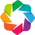

SpatailDM version: 0.2.0


In [3]:
import spatialdm as sdm
from spatialdm.datasets import dataset
import spatialdm.plottings as pl

import matplotlib.pyplot as plt
print("SpatailDM version: %s" %sdm.__version__)

In [4]:
import sys

notebook_dir = os.getcwd() 


project_root = os.path.dirname(notebook_dir)


if project_root not in sys.path:
    sys.path.insert(0, project_root)

In [5]:
from SparseAEH import *

In [6]:
from tensorflow_probability import math as tm
tfk = tm.psd_kernels

2026-10-28 09:23:11.540562: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-28 09:23:11.761487: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793150591.868449  615576 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793150591.895060  615576 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-28 09:23:12.126477: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

In [7]:
import SpatialDE
import NaiveDE

In [8]:
from nsf_paper.models import sf
from nsf_paper.utils import misc,preprocess,training,postprocess,visualize

In [9]:
from mofapy2.run.entry_point import entry_point
import mofax

In [10]:
# Run after imports; rerun setup and experiment cells when changing seeds.
import random
import tensorflow as tf
from SparseAEH.benchmark_logging import BenchmarkRecorder, sparseaeh_details

tf.config.set_visible_devices([], "GPU")

SEED = 0

def reset_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)
    # NSF uses a separate NumPy generator.
    sf.rng = np.random.default_rng(SEED)

reset_seed()
bench = BenchmarkRecorder('demo.ipynb', seed=SEED)
print("Seed:", SEED)
print("Environment:", bench.environment_path)
print("Run records:", bench.runs_path)


W0000 00:00:1793150606.615744  615576 gpu_device.cc:2344] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Seed: 0
Environment: /grp01/sbms_yhhuang/tianjie/AEH/benchmark_logs/environment_20261028T012326Z_615576_0a7a5a6c.json
Run records: /grp01/sbms_yhhuang/tianjie/AEH/benchmark_logs/runs_20261028T012326Z_615576_0a7a5a6c.jsonl


# NSF - quilt

In [16]:
reset_seed()
#%% Data loading
adata = sc.read_h5ad("nsf_paper/simulations/bm_sp/data/S1.h5ad")
adata = adata[:,:80]
X = adata.obsm["spatial"]
#raw count data for NSF
D,Dval = preprocess.anndata_to_train_val(adata, layer="counts", train_frac=0.8,
                                         flip_yaxis=False)
Ntr,J = D["Y"].shape
Xtr = D["X"]
adata = adata[:Ntr,:]
#convert to tensorflow objects
Dtf = preprocess.prepare_datasets_tf(D,Dval=Dval)

W0000 00:00:1772203060.992961 1910963 gpu_device.cc:2344] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [ ]:
# adata.layers['counts'] == adata

ValueError: setting an array element with a sequence. The requested array would exceed the maximum number of dimension of 32.

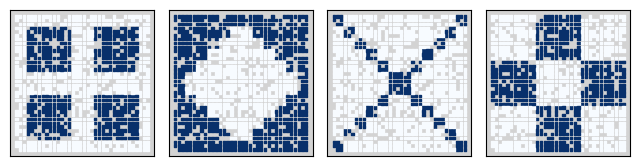

In [18]:
#%% Heatmap of true values
hmkw1 = {"figsize":(8,1.9), "bgcol":"lightgray", "subplot_space":0.1, "marker":"s",
        "s":2.9}
Ftrue = adata.obsm["spfac"]
fig,axes=visualize.multiheatmap(Xtr, Ftrue, (1,4), cmap="Blues", **hmkw1)
fig.savefig("true.pdf")

In [19]:
expression = pd.DataFrame(adata.X)

In [20]:
reset_seed()
with bench.run(
    method='SpatialDE', dataset='quilt_S1',
    scope='SVG detection and AEH pattern extraction',
    parameters={'method_seed': SEED, 'C': 4, 'l': 0.1},
    input_shape=expression.shape, device='cpu'
) as bench_run:
    start = time.perf_counter()

    results = SpatialDE.run(adata.obsm['spatial'], expression)

    patterns, mean = SpatialDE.aeh.spatial_patterns(adata.obsm['spatial'], expression,results,C=4,l=0.1)
    end = time.perf_counter()
    bench_run.finish_timing(end - start)
DE_time = end-start

Models: 100%|██████████| 10/10 [00:01<00:00,  5.36it/s]


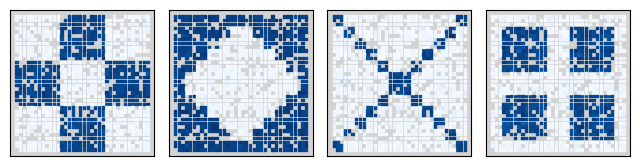

In [74]:
fig,axes=visualize.multiheatmap(Xtr, np.array(mean), (1,4), cmap="Blues", **hmkw1)
fig.savefig('DE_sim.pdf')

In [32]:
reset_seed()
with bench.run(
    method='SparseAEH', dataset='quilt_S1',
    scope='model construction and fitting',
    parameters={'method_seed': SEED, 'internal_kmeans_random_state': 0, 'group_size': 16, 'd': 30, 'l': 1e-2, 'K': 4, 'max_iter': 50, 'threshold': 8e-2, 'initialization': 'k_means'},
    input_shape=adata.X.shape, device='cpu'
) as bench_run:
    start = time.perf_counter()
    gaussian_sim = MixedGaussian(adata.obsm['spatial'],group_size=16,d=30,l=1e-2)
    cluster_sim = gaussian_sim.run_cluster(adata.X,4,iter=50,init_mean='k_means',threshold=8e-2) 
    end = time.perf_counter()
    bench_run.finish_timing(end - start)
    bench_run.details.update(sparseaeh_details(gaussian_sim))
AEH_time = end-start

Iteration 0
Iteration 1
updating variance
Iteration 2


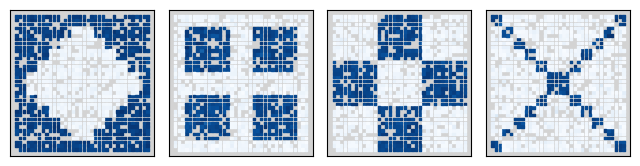

In [33]:
fig,axes=visualize.multiheatmap(Xtr, cluster_sim, (1,4), cmap="Blues", **hmkw1)
fig.savefig('AEH_sim.pdf')

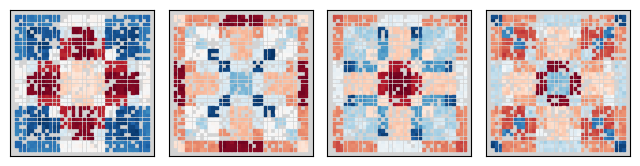

In [58]:
reset_seed()
#%% Scanpy PCA dimension reduction
with bench.run(
    method='PCA', dataset='quilt_S1',
    scope='PCA and visualization, as in original timer',
    parameters={'method_seed': SEED},
    input_shape=adata.X.shape, device='cpu'
) as bench_run:
    start = time.perf_counter()
    sc.pp.pca(adata, random_state=SEED)
    fig,axes=visualize.multiheatmap(Xtr, adata.obsm["X_pca"][:,:4], (1,4), cmap="RdBu",
                                    **hmkw1)
    fig.savefig('pca_sim.pdf')
    end = time.perf_counter()
    bench_run.finish_timing(end - start)
pca_time = end-start

In [35]:
reset_seed()
#%% NSF
L = 4 #number of components
Z = misc.kmeans_inducing_pts(Xtr, 500)
M = Z.shape[0] #number of inducing points
ker = tfk.MaternThreeHalves

with bench.run(
    method='NSF', dataset='quilt_S1',
    scope='model construction, fitting and interpretation; excludes inducing-point selection',
    parameters={'method_seed': SEED, 'factors': L, 'inducing_points': M, 'kernel': 'MaternThreeHalves', 'likelihood': 'poi', 'nonnegative': True, 'interpretation_samples': 100},
    input_shape=D["Y"].shape, device='auto'
) as bench_run:
    start = time.perf_counter()
    fit = sf.SpatialFactorization(J, L, Z, psd_kernel=ker, nonneg=True, lik="poi")
    fit.init_loadings(D["Y"], X=Xtr, sz=D["sz"], shrinkage=0.3)
    tro = training.ModelTrainer(fit)
    tro.train_model(*Dtf, status_freq=50) #about 3 mins
    #visualize.plot_loss(tro.loss)

    insf = postprocess.interpret_nsf(fit,Xtr,S=100,lda_mode=False)
    Fplot = insf["factors"][:,[2,0,3,1]]

    end = time.perf_counter()
    bench_run.finish_timing(end - start)
nsf_time = end-start

Temporary checkpoint directory: /tmp/tmp0wh03ezs


2026-02-05 11:16:59.766966: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-02-05 11:17:00.080461: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-02-05 11:17:00.529872: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-02-05 11:17:01.390882: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-02-05 11:17:02.948141: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-02-05 11:17:07.266048: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


0050 train: 4.541e+02, val: 5.944e+02


2026-02-05 11:17:14.653431: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


0100 train: 4.112e+02, val: 5.934e+02


...

1050 train: 3.294e+02, val: 5.493e+02, chg: -2.35e-04
1100 train: 3.265e+02, val: 5.654e+02, chg: -9.09e-05
1150 train: 3.267e+02, val: 5.405e+02, chg: 2.67e-04
1200 train: 3.282e+02, val: 5.517e+02, chg: -7.46e-04
1250 train: 3.230e+02, val: 5.282e+02, chg: -2.22e-04
1300 train: 3.239e+02, val: 5.489e+02, chg: 3.13e-04
1350 train: 3.250e+02, val: 5.511e+02, chg: -4.25e-04
1400 train: 3.261e+02, val: 5.410e+02, chg: -1.40e-04
1450 train: 3.297e+02, val: 5.568e+02, chg: -4.12e-04
1500 train: 3.267e+02, val: 5.404e+02, chg: -5.19e-04
1550 train: 3.214e+02, val: 5.547e+02, chg: -1.37e-04
1600 train: 3.214e+02, val: 5.443e+02, chg: 2.59e-04
1650 train: 3.223e+02, val: 5.319e+02, chg: -1.96e-04
1700 train: 3.247e+02, val: 5.263e+02, chg: -2.16e-04
1750 train: 3.174e+02, val: 5.446e+02, chg: -1.36e-04
1800 train: 3.268e+02, val: 5.349e+02, chg: 4.03e-04
1850 train: 3.168e+02, val: 5.255e+02, chg: 6.88e-04
1900 train: 3.307e+02, val: 5.244e+02, chg: -5.66e-05
1950 train: 3.217e+02, val: 5.387

2026-02-05 11:24:01.900890: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


2050 train: 3.169e+02, val: 5.305e+02, chg: -5.44e-05
2100 train: 3.201e+02, val: 5.646e+02, chg: -3.15e-04
2150 train: 3.260e+02, val: 5.509e+02, chg: -1.39e-04
2200 train: 3.168e+02, val: 5.207e+02, chg: 2.00e-04
2250 train: 3.172e+02, val: 5.243e+02, chg: -1.21e-04
2300 train: 3.222e+02, val: 5.269e+02, chg: -5.92e-04
2350 train: 3.268e+02, val: 5.207e+02, chg: -1.87e-04
2400 train: 3.246e+02, val: 5.395e+02, chg: -2.97e-04
2450 train: 3.255e+02, val: 5.271e+02, chg: 6.88e-05
2500 train: 3.209e+02, val: 5.285e+02, chg: 1.48e-04
2550 train: 3.244e+02, val: 5.395e+02, chg: 5.48e-04
2600 train: 3.237e+02, val: 5.461e+02, chg: -1.88e-04
2650 train: 3.225e+02, val: 5.322e+02, chg: 7.17e-06
2700 train: 3.172e+02, val: 5.162e+02, chg: -6.21e-05
2750 train: 3.213e+02, val: 5.238e+02, chg: -4.22e-05
2800 train: 3.176e+02, val: 5.332e+02, chg: -3.73e-04
2850 train: 3.214e+02, val: 5.251e+02, chg: 7.71e-05
2900 train: 3.119e+02, val: 5.382e+02, chg: 2.52e-04
2950 train: 3.127e+02, val: 5.379e+

2026-02-05 11:30:59.111729: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


4100 train: 3.145e+02, val: 5.227e+02, chg: 1.60e-04
4150 train: 3.131e+02, val: 5.472e+02, chg: -1.17e-04
4200 train: 3.106e+02, val: 5.494e+02, chg: 6.77e-04
4250 train: 3.115e+02, val: 5.446e+02, chg: 3.63e-04
4300 train: 3.147e+02, val: 5.449e+02, chg: -6.50e-04
4350 train: 3.111e+02, val: 5.225e+02, chg: -5.81e-04
4400 train: 3.121e+02, val: 5.248e+02, chg: 1.76e-04
4450 train: 3.135e+02, val: 5.218e+02, chg: -4.77e-04
4500 train: 3.168e+02, val: 5.388e+02, chg: 3.00e-04
4550 train: 3.177e+02, val: 5.505e+02, chg: -5.44e-05
4600 train: 3.124e+02, val: 5.302e+02, chg: -6.78e-04
4650 train: 3.104e+02, val: 5.160e+02, chg: 4.86e-04
4700 train: 3.066e+02, val: 5.312e+02, chg: 4.82e-04
4750 train: 3.130e+02, val: 5.337e+02, chg: -1.16e-04
4800 train: 3.114e+02, val: 5.171e+02, chg: 3.83e-04
4850 train: 3.125e+02, val: 5.219e+02, chg: -2.40e-04
4900 train: 3.094e+02, val: 5.217e+02, chg: -1.37e-04
4950 train: 3.080e+02, val: 5.212e+02, chg: 2.37e-04
5000 train: 3.119e+02, val: 5.333e+02

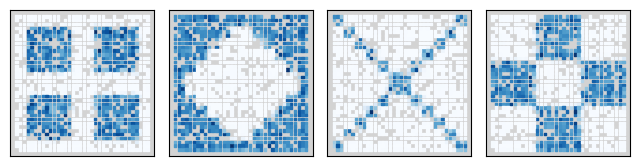

In [ ]:
insf = postprocess.interpret_nsf(fit,Xtr,S=100,lda_mode=False)
Fplot = insf["factors"][:,[2,0,3,1]]
fig,axes=visualize.multiheatmap(Xtr, Fplot, (1,4), cmap="Blues", **hmkw1)
fig.savefig('nsf_sim.pdf')

In [ ]:
reset_seed()
ent = entry_point()


        #########################################################
        ###           __  __  ____  ______                    ### 
        ###          |  \/  |/ __ \|  ____/\    _             ### 
        ###          | \  / | |  | | |__ /  \ _| |_           ### 
        ###          | |\/| | |  | |  __/ /\ \_   _|          ###
        ###          | |  | | |__| | | / ____ \|_|            ###
        ###          |_|  |_|\____/|_|/_/    \_\              ###
        ###                                                   ### 
        ######################################################### 
         




In [39]:
ent.set_data_options(use_float32=True)

use_float32 set to True: replacing float64 arrays by float32 arrays to speed up computations...



In [40]:
ent.set_data_from_anndata(adata)

Loaded view='rna' group='group1' with N=1037 samples and D=80 features...




In [41]:
ent.set_model_options(factors=4)
ent.set_train_options(seed=SEED)

Model options:
- Automatic Relevance Determination prior on the factors: False
- Automatic Relevance Determination prior on the weights: True
- Spike-and-slab prior on the factors: False
- Spike-and-slab prior on the weights: True
Likelihoods:
- View 0 (rna): gaussian




In [42]:
ent.set_train_options(seed=SEED)

In [43]:
n_inducing = 500

ent.set_covariates([adata.obsm["spatial"]], covariates_names=["imagerow", "imagecol"])
ent.set_smooth_options(sparseGP=True, frac_inducing=n_inducing/adata.n_obs,
                       start_opt=10, opt_freq=10)

Loaded 2 covariate(s) for each sample...


##
## sparseGP set to True: using sparse Gaussian Process to speed up the training procedure
##


In [44]:
ent.build()
with bench.run(
    method='MEFISTO', dataset='quilt_S1',
    scope='ent.run only; excludes build and saving',
    parameters={'factors': 4, 'inducing_points': n_inducing, 'method_seed': SEED, 'sparseGP': True},
    input_shape=adata.X.shape, device='auto'
) as bench_run:
    start = time.perf_counter()
    ent.run()
    end = time.perf_counter()
    bench_run.finish_timing(end - start)
mef_time = end - start
ent.save("ST_model.hdf5")



######################################
## Training the model with seed 2021 ##
######################################


ELBO before training: -403384.73 

Iteration 1: time=0.52, ELBO=-75862.97, deltaELBO=327521.753 (81.19339460%), Factors=4
Iteration 2: time=1.41, ELBO=-58447.37, deltaELBO=17415.599 (4.31736699%), Factors=4
Iteration 3: time=0.46, ELBO=-58646.22, deltaELBO=-198.849 (0.04929509%), Factors=4
Warning, lower bound is decreasing...
Iteration 4: time=1.36, ELBO=-58683.43, deltaELBO=-37.204 (0.00922300%), Factors=4
Warning, lower bound is decreasing...
Iteration 5: time=1.59, ELBO=-58608.62, deltaELBO=74.804 (0.01854399%), Factors=4
Iteration 6: time=0.60, ELBO=-58530.77, deltaELBO=77.854 (0.01930028%), Factors=4
Iteration 7: time=1.18, ELBO=-58458.22, deltaELBO=72.549 (0.01798508%), Factors=4
Iteration 8: time=1.11, ELBO=-58391.04, deltaELBO=67.179 (0.01665371%), Factors=4
Iteration 9: time=0.92, ELBO=-58328.77, deltaELBO=62.268 (0.01543642%), Factors=4
Optimising sigma

In [45]:
import mofax
m = mofax.mofa_model("ST_model.hdf5")

In [46]:
clusters = m.get_factors()

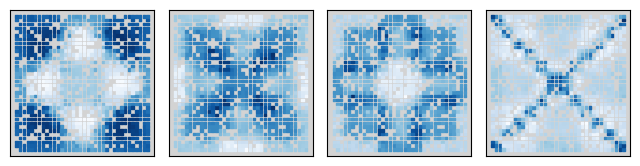

In [47]:
fig,axes=visualize.multiheatmap(Xtr, clusters, (1,4), cmap="Blues", **hmkw1)
fig.savefig('mef_sim.pdf')

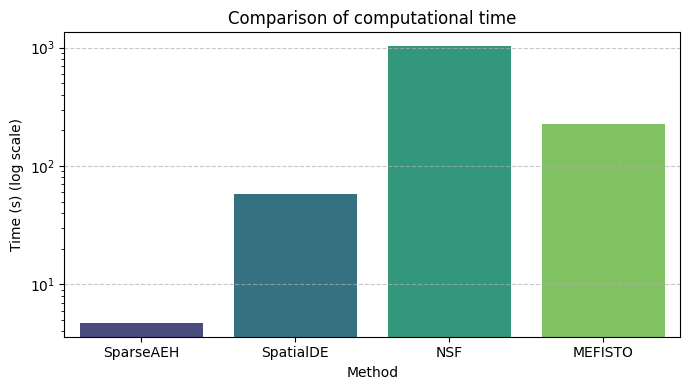

In [52]:
data = {
    'Method': ['SparseAEH', 'SpatialDE','NSF', 'MEFISTO'],
    'Time': [AEH_time, DE_time, nsf_time, mef_time]
}
df = pd.DataFrame(data)


plt.figure(figsize=(7, 4))
ax = sns.barplot(x='Method', y='Time', data=df, palette='viridis')

ax.set_yscale('log')

plt.ylabel('Time (s) (log scale)') 
plt.title('Comparison of computational time')


plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('time_sim_log.svg')

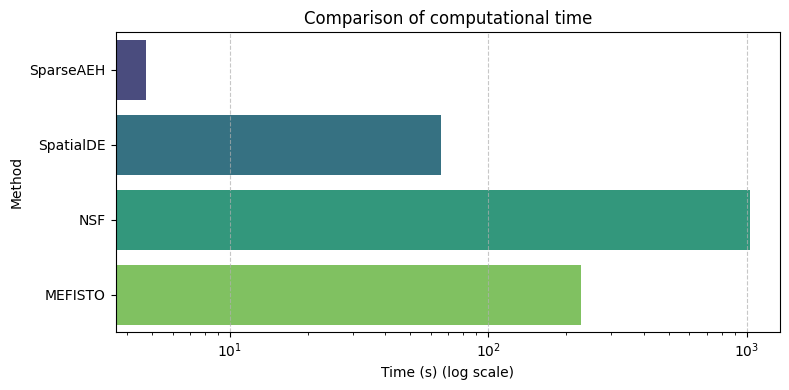

In [77]:
data = {
    'Method': ['SparseAEH', 'SpatialDE','NSF', 'MEFISTO'],
    'Time': [AEH_time, DE_time, nsf_time, mef_time
    ]
}
df = pd.DataFrame(data)


plt.figure(figsize=(8, 4))
ax = sns.barplot(x='Time', y='Method', data=df, palette='viridis')

ax.set_xscale('log')

plt.xlabel('Time (s) (log scale)') 
plt.title('Comparison of computational time')


plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('time_sim_log.pdf')

# NPC

In [11]:
NPC_1_PATH = '/grp01/sbms_yhhuang/lingyu/STFoundation/Data/NPC/patient1_adata_all_pvalue.h5ad'
adata_impt_all_spot = ad.read(NPC_1_PATH)
adata_impt_all_spot.uns['single_cell'] = False

In [12]:
sdm.extract_lr(adata_impt_all_spot, 'human', min_cell=3)

In [13]:
reset_seed()
sdm.spatialdm_global(adata_impt_all_spot, n_perm=1000, specified_ind=None, method='z-score', nproc=1)
# select significant pairs
sdm.sig_pairs(adata_impt_all_spot, method='z-score', fdr=True, threshold=0.05)  # , threshold=0.1

In [14]:
reset_seed()
sdm.spatialdm_local(adata_impt_all_spot, n_perm=1000, method='z-score', specified_ind=None, nproc=1)
# significant local spots
sdm.sig_spots(adata_impt_all_spot, method='z-score', fdr=False, threshold=0.05)  # , threshold=0.1

In [11]:
adata_impt_all_spot.uns["local_z_p"]

NameError: name 'adata_impt_all_spot' is not defined

In [16]:
bin_allspots = (1-adata_impt_all_spot.uns["local_z_p"])[adata_impt_all_spot.uns['local_stat']['n_spots']>2]
Y = bin_allspots.to_numpy()
X = adata_impt_all_spot.obsm['spatial']

In [17]:
reset_seed()
with bench.run(
    method='SparseAEH', dataset=NPC_1_PATH,
    scope='model construction and fitting on 1-pvalue LR profiles',
    parameters={'method_seed': SEED, 'internal_kmeans_random_state': 0, 'group_size': 16, 'd': 30, 'l': 1e-5, 'K': 3, 'max_iter': 50, 'initialization': 'k_means'},
    input_shape=Y.T.shape, device='cpu'
) as bench_run:
    start = time.perf_counter()
    gaussian_1 = MixedGaussian(adata_impt_all_spot.obsm['spatial'],group_size=16,d=30,l=1e-5)
    cluster_1 = gaussian_1.run_cluster(Y.T,3,iter=50,init_mean='k_means') 
    end = time.perf_counter()
    bench_run.finish_timing(end - start)
    bench_run.details.update(sparseaeh_details(gaussian_1))
aeh_time = end - start
print(aeh_time)

# gaussian_sim = MixedGaussian(adata.obsm['spatial'],group_size=16,d=30,l=1e-2)
# cluster_sim = gaussian_sim.run_cluster(adata.X,4,iter=50,init_mean='k_means',threshold=8e-2) 

Iteration 0
updating variance
Iteration 1
28.876299619674683


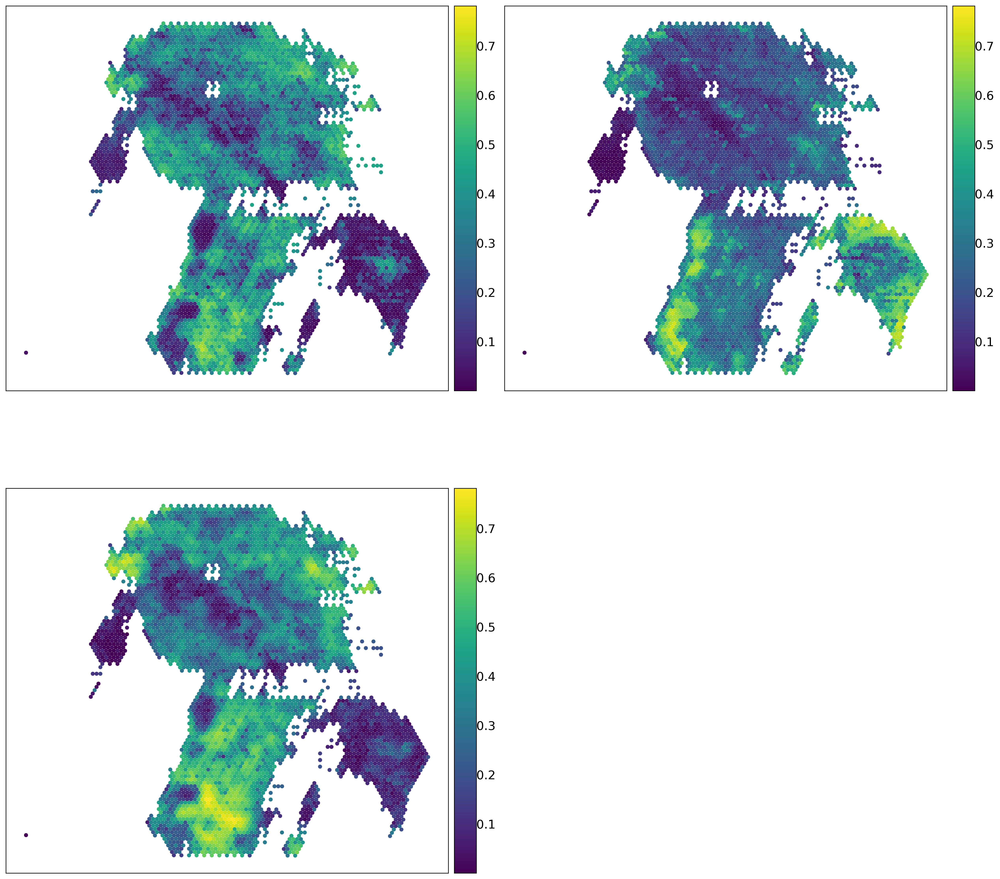

In [17]:
plot_clusters(mean=gaussian_1.mean, spatial=adata_impt_all_spot.obsm['spatial'], #count = [202,425,157],
                 label='pairs', figsize=None, s=15, base_subplot_size_inches=(8, 8), save='npc_aeh.pdf')

In [ ]:
# reset_seed()
# Uncomment this cell to record a new NPC SpatialDE run.
# with bench.run(
#     method='SpatialDE', dataset=NPC_1_PATH,
#     scope='SVG detection and AEH pattern extraction on LR profiles',
#     parameters={'method_seed': SEED, 'C': 3, 'l': 3, 'verbosity': 1},
#     input_shape=bin_allspots.transpose().shape, device='cpu'
# ) as bench_run:
#     start = time.perf_counter()
#     results = SpatialDE.run(adata_impt_all_spot.obsm['spatial'], bin_allspots.transpose())

#     histology_results_allspot, patterns_allspot = SpatialDE.aeh.spatial_patterns(
#             adata_impt_all_spot.obsm['spatial'], bin_allspots.transpose(), results, C=3, l=3, verbosity=1)

#     end = time.perf_counter()
#     bench_run.finish_timing(end - start)
# de_time = end - start

Models: 100%|██████████| 10/10 [01:12<00:00,  7.20s/it]


iter 0, ELBO: -6.63e+04
iter 1, ELBO: -6.79e+06, delta_ELBO: 6.73e+06
iter 2, ELBO: -7.43e+06, delta_ELBO: 6.37e+05
iter 3, ELBO: -7.62e+06, delta_ELBO: 1.88e+05
iter 4, ELBO: -7.76e+06, delta_ELBO: 1.37e+05
iter 5, ELBO: -7.79e+06, delta_ELBO: 3.85e+04
iter 6, ELBO: -7.80e+06, delta_ELBO: 3.20e+03
iter 7, ELBO: -7.80e+06, delta_ELBO: 7.07e+02
iter 8, ELBO: -7.80e+06, delta_ELBO: 3.27e+02
iter 9, ELBO: -7.80e+06, delta_ELBO: 4.65e+01
iter 10, ELBO: -7.80e+06, delta_ELBO: 1.81e+02
iter 11, ELBO: -7.80e+06, delta_ELBO: 4.38e+01
iter 12, ELBO: -7.80e+06, delta_ELBO: 5.16e+01
iter 13, ELBO: -7.80e+06, delta_ELBO: 4.23e+01
iter 14, ELBO: -7.80e+06, delta_ELBO: 1.81e-02
iter 15, ELBO: -7.80e+06, delta_ELBO: 8.73e-02
iter 16, ELBO: -7.80e+06, delta_ELBO: 4.32e-02
iter 17, ELBO: -7.80e+06, delta_ELBO: 6.26e-02
iter 18, ELBO: -7.80e+06, delta_ELBO: 6.22e-02
iter 19, ELBO: -7.80e+06, delta_ELBO: 3.83e-07
Converged on iter 19


In [18]:
de_time = 10577.48963689804

In [32]:
print(de_time)
np.save('npc_de.npy',np.array(patterns_allspot))
histology_results_allspot.to_csv('output.csv',index=False)

10577.48963689804


In [17]:
de_output = pd.read_csv('output.csv')
de_output

,g,pattern,membership
0,EFNA5_EPHB2,1,1.0
1,EFNB1_EPHA4,1,1.0
2,EFNB1_EPHB1,1,1.0
3,EFNB1_EPHB2,1,1.0
4,EFNB1_EPHB3,1,1.0
...,...,...,...
779,CXCL1_ACKR1,2,1.0
780,CORT_SSTR2,1,1.0
781,CCL14_ACKR1,2,1.0
782,CCL13_ACKR1,2,1.0


In [21]:
de_output['pattern'].value_counts()

pattern
1    425
0    202
2    157
Name: count, dtype: int64

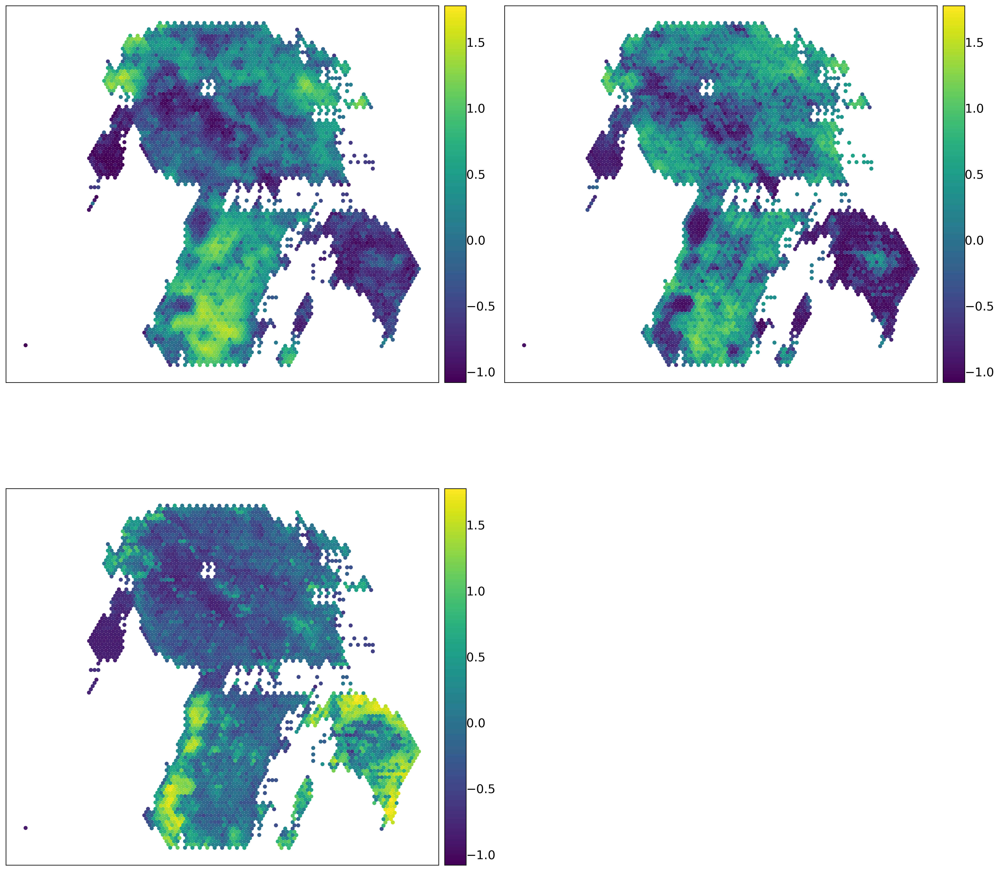

In [18]:
de_mean = np.load('npc_de.npy')
plot_clusters(mean=de_mean, spatial=adata_impt_all_spot.obsm['spatial'], #count = [202,425,157],
                 label='pairs', figsize=None, s=15, base_subplot_size_inches=(8, 8), save='npc_de.pdf')

In [19]:
adata_spot = ad.AnnData(X=bin_allspots.values.T, obs=bin_allspots.columns.to_frame(),
                                var=bin_allspots.index.to_frame())
adata_spot.obsm['spatial'] = adata_impt_all_spot.obsm['spatial']
adata_spot

AnnData object with n_obs × n_vars = 5039 × 784
    obs: 0
    var: 0
    obsm: 'spatial'

In [20]:
reset_seed()
D,Dval = preprocess.anndata_to_train_val(adata_spot, train_frac=1.0,
                                         flip_yaxis=False)
Ntr,J = D["Y"].shape
Xtr = D["X"]
Dtf = preprocess.prepare_datasets_tf(D,Dval=Dval)

L = 3 #number of components
Z = misc.kmeans_inducing_pts(adata_spot.obsm['spatial'], 500)
M = Z.shape[0] #number of inducing points
ker = tfk.MaternThreeHalves

with bench.run(
    method='NSF', dataset=NPC_1_PATH,
    scope='model construction, fitting and interpretation; excludes preprocessing and inducing-point selection',
    parameters={'method_seed': SEED, 'factors': L, 'inducing_points': M, 'kernel': 'MaternThreeHalves', 'likelihood': 'poi', 'nonnegative': True, 'interpretation_samples': 100},
    input_shape=D["Y"].shape, device='auto'
) as bench_run:
    start = time.perf_counter()
    fit = sf.SpatialFactorization(J, L, Z, psd_kernel=ker, nonneg=True, lik="poi")
    fit.init_loadings(D['Y'], X=D['X'], sz=D["sz"], shrinkage=0.3)
    tro = training.ModelTrainer(fit)
    tro.train_model(*Dtf, status_freq=50) #about 3 mins
    #visualize.plot_loss(tro.loss)

    insf = postprocess.interpret_nsf(fit,D['X'],S=100,lda_mode=False)

    end = time.perf_counter()
    bench_run.finish_timing(end - start)
nsf_time = end-start

W0000 00:00:1772272148.187782 2101410 gpu_device.cc:2344] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Temporary checkpoint directory: /tmp/tmp4bhw9rhc


2026-02-28 17:49:21.397672: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-02-28 17:49:22.020833: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-02-28 17:49:23.290388: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-02-28 17:49:25.844009: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-02-28 17:49:33.161109: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-02-28 17:49:45.515447: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


0050 train: 6.117e+07


2026-02-28 17:50:09.523467: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


...

0150 train: 2.689e+06, chg: 3.20e+00
0200 train: 6.182e+05, chg: 3.77e-02
0250 train: 1.252e+05, chg: 6.33e-02


2026-02-28 17:52:22.733832: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


0300 train: 2.421e+04, chg: 9.44e-02
0350 train: 4.935e+03, chg: 1.05e-01
0400 train: 1.403e+03, chg: 6.67e-02
0450 train: 7.656e+02, chg: 2.10e-02
0500 train: 6.372e+02, chg: 4.79e-03


2026-02-28 17:55:21.155981: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


0550 train: 6.055e+02, chg: 1.11e-03
0600 train: 5.949e+02, chg: 2.93e-04
0650 train: 5.931e+02, chg: 6.27e-05
0700 train: 5.916e+02, chg: 9.58e-05
0750 train: 5.901e+02, chg: 3.49e-05
0800 train: 5.891e+02, chg: 7.54e-07
0800 training complete, converged.


In [21]:
Fplot = insf["factors"]
counts = insf['totals']
Fplot.shape

(5039, 3)

In [22]:
np.save('npc_nsf.npy', Fplot)
np.save('npc_nsf_count.npy',counts)
print(nsf_time)

577.0874099731445


In [19]:
# Historical value retained for reference.
legacy_nsf_time = 577.0874099731445

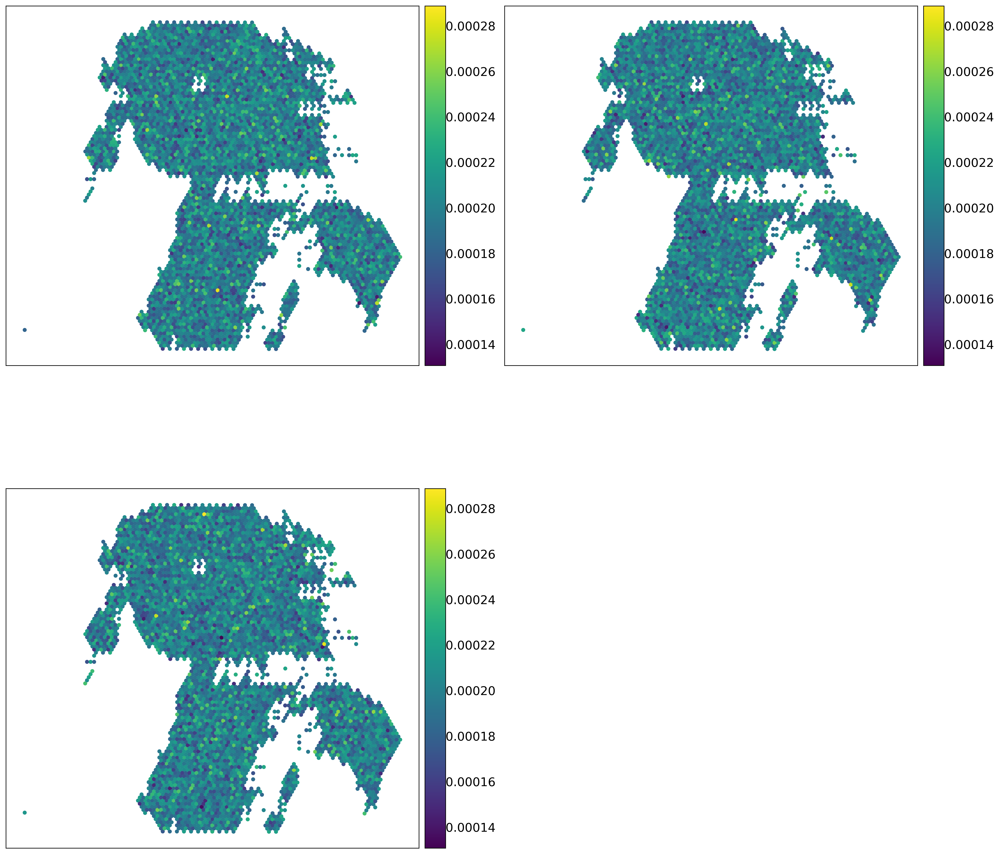

In [23]:
plot_clusters(mean=Fplot, spatial=adata_impt_all_spot.obsm['spatial'], #count = counts,
                 label='genes', figsize=None, s=15, base_subplot_size_inches=(8, 8),save = 'npc_nsf.pdf')

In [24]:
reset_seed()
ent = entry_point()
ent.set_data_options(use_float32=True)
ent.set_data_from_anndata(adata_spot)

ent.set_model_options(factors=3)
ent.set_train_options(seed=SEED)

n_inducing = 500

ent.set_covariates([adata_spot.obsm["spatial"]], covariates_names=["imagerow", "imagecol"])
ent.set_smooth_options(sparseGP=True, frac_inducing=n_inducing/adata_spot.n_obs,
                       start_opt=10, opt_freq=10)

ent.build()
with bench.run(
    method='MEFISTO', dataset=NPC_1_PATH,
    scope='ent.run only; excludes build',
    parameters={'factors': 3, 'inducing_points': n_inducing, 'sparseGP': True, 'method_seed': SEED},
    input_shape=adata_spot.X.shape, device='auto'
) as bench_run:
    start = time.perf_counter()
    ent.run()
    end = time.perf_counter()
    bench_run.finish_timing(end - start)
mef_time = end - start


        #########################################################
        ###           __  __  ____  ______                    ### 
        ###          |  \/  |/ __ \|  ____/\    _             ### 
        ###          | \  / | |  | | |__ /  \ _| |_           ### 
        ###          | |\/| | |  | |  __/ /\ \_   _|          ###
        ###          | |  | | |__| | | / ____ \|_|            ###
        ###          |_|  |_|\____/|_|/_/    \_\              ###
        ###                                                   ### 
        ######################################################### 
         


use_float32 set to True: replacing float64 arrays by float32 arrays to speed up computations...

Loaded view='rna' group='group1' with N=5039 samples and D=784 features...


Model options:
- Automatic Relevance Determination prior on the factors: False
- Automatic Relevance Determination prior on the weights: True
- Spike-and-slab prior on the factors: False
- Spike-and-slab prior on t

In [25]:
print(mef_time)
ent.save('NPC_model.hdf5')

447.5984706878662
Saving model in NPC_model.hdf5...


In [19]:
print(mef_time)
ent.save('NPC_model.hdf5')

14246.103643417358
Saving model in NPC_model.hdf5...


In [20]:
# Historical value retained for reference.
legacy_mef_time = 14246.103643417358

In [24]:
m = mofax.mofa_model("NPC_model.hdf5")
clusters = m.get_factors()

In [57]:
unique_values, counts = np.unique(np.argmax(m.get_weights(), axis=1), return_counts=True)

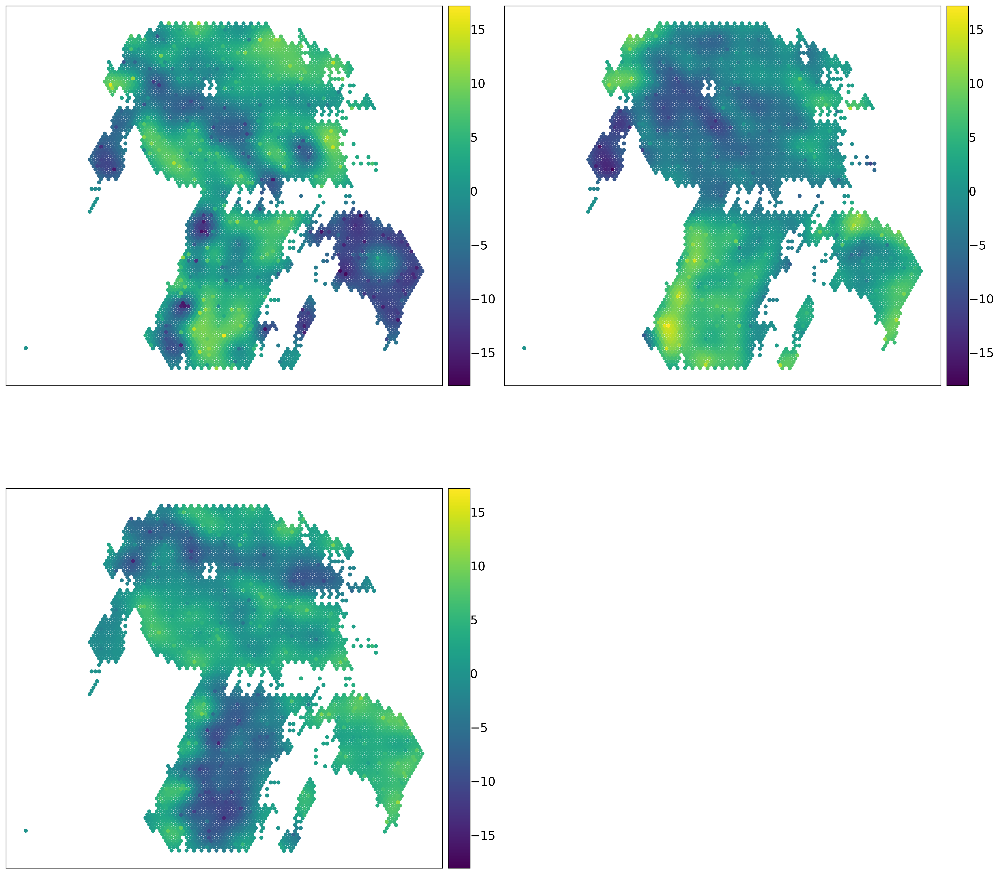

In [25]:
plot_clusters(mean=clusters, spatial=adata_impt_all_spot.obsm['spatial'], #count = counts,
                 label='pairs', figsize=None, s=15, base_subplot_size_inches=(8, 8),save = 'npc_mef.pdf')

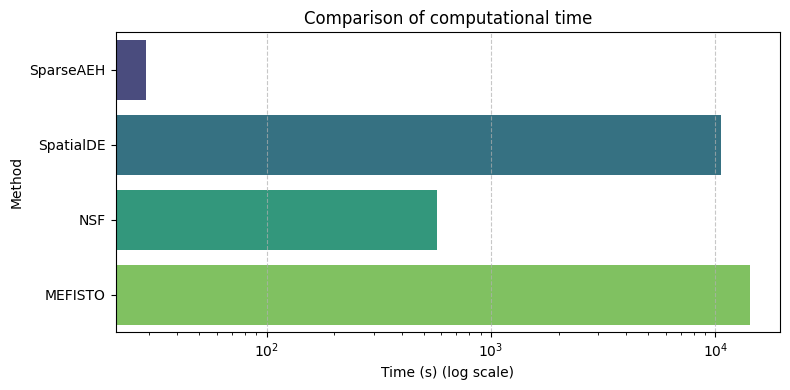

In [21]:
data = {
    'Method': ['SparseAEH', 'SpatialDE','NSF', 'MEFISTO'],
    'Time': [aeh_time, de_time, nsf_time, mef_time
    ]
}
df = pd.DataFrame(data)


plt.figure(figsize=(8, 4))
ax = sns.barplot(x='Time', y='Method', data=df, palette='viridis')

ax.set_xscale('log')

plt.xlabel('Time (s) (log scale)') 
plt.title('Comparison of computational time')


plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('time_npc_log.pdf')

# NPC1-genes

Use the current NPC file's `.X` as FineST-imputed expression, not original counts, with matching coordinates from `.obsm['spatial']`. Filter constant or nearly constant genes, then center and scale each retained gene across locations to study relative spatial patterns rather than absolute abundance. The original `.X` remains unchanged.

Retain genes whose population standard deviation exceeds `NPC_MIN_REL_SD` times their maximum absolute expression. The default `1e-6` is a numerical near-constant cutoff, not a biological expression or spatial-significance threshold. Gene-wise standardization follows the step inside SpatialDE's [AEH wrapper](https://github.com/Teichlab/SpatialDE/blob/master/Python-module/SpatialDE/aeh.py); it does not establish Gaussian model adequacy or validate spatial significance in imputed data.

No log transformation, library-size normalization, depth regression, or NaiveDE count stabilization is applied. Standardized values can be negative, and a cluster profile's average across locations can naturally be near zero; assess its spatial variation instead. Preprocessing and fitting are recorded separately, excluding file loading and dense conversion.


In [11]:
NPC_GENE_PATH = '/grp01/sbms_yhhuang/lingyu/STFoundation/Data/NPC/patient1_adata_all_pvalue.h5ad'
NPC_MIN_REL_SD = 1e-6
adata_npc_genes = ad.read_h5ad(NPC_GENE_PATH)


In [12]:
npc_gene_expr = adata_npc_genes.to_df()
npc_spatial = np.asarray(adata_npc_genes.obsm['spatial'])
print(npc_gene_expr.shape[0], 'locations and', npc_gene_expr.shape[1], 'input genes')


5039 locations and 596 input genes


In [14]:
with bench.run(
    method='Gene-wise standardization', dataset='NPC1_genes',
    scope='near-constant gene filtering and standardization; excludes file loading and dense conversion',
    parameters={'method_seed': SEED, 'deterministic': True,
                'input_file': NPC_GENE_PATH, 'expression_source': '.X',
                'input_type': 'FineST-imputed gene expression',
                'min_relative_sd': NPC_MIN_REL_SD, 'std_ddof': 0},
    input_shape=npc_gene_expr.shape, device='cpu'
) as prep_run:
    if not np.isfinite(npc_gene_expr.to_numpy()).all():
        raise ValueError('NPC expression contains non-finite values.')
    npc_gene_mean = npc_gene_expr.mean(axis=0)
    npc_gene_sd = npc_gene_expr.std(axis=0, ddof=0)
    npc_gene_keep = npc_gene_sd > NPC_MIN_REL_SD * npc_gene_expr.abs().max(axis=0)
    if npc_gene_keep.sum() < 3:
        raise ValueError('At least three retained genes are needed for K=3.')
    npc_gene_standardized = (
        npc_gene_expr.loc[:, npc_gene_keep] - npc_gene_mean.loc[npc_gene_keep]
    ) / npc_gene_sd.loc[npc_gene_keep]
    npc_gene_input = npc_gene_standardized.to_numpy()
    prep_run.finish_timing()
    prep_run.details.update({
        'retained_genes': npc_gene_standardized.columns.tolist(),
        'dropped_genes': npc_gene_expr.columns[~npc_gene_keep].tolist(),
        'input_gene_means': npc_gene_mean.tolist(),
        'input_gene_sds': npc_gene_sd.tolist(),
        'input_gene_names': npc_gene_expr.columns.tolist(),
        'output_shape': npc_gene_input.shape,
    })
print(npc_gene_input.shape[1], 'genes retained;', int((~npc_gene_keep).sum()), 'near-constant genes removed')


Benchmark recorded [ok]: Gene-wise standardization, 0.057 s -> /grp01/sbms_yhhuang/tianjie/AEH/benchmark_logs/runs_20261028T012326Z_615576_0a7a5a6c.jsonl
596 genes retained; 0 near-constant genes removed


In [ ]:
from random import sample
from sklearn.cluster import KMeans

NPC_GEM_K = 3
NPC_GEM_KERNEL = {'kernel': 'rbf', 'l': 1e-5}
NPC_GEM_FIT = {
    'iter': 50, 'threshold': 8e-2, 'likelihood_tolerance': 1e-6,
    'update_pi': True, 'covariance_update': 'line_search',
    'delta_bounds': (0.0, 10.0), 'scale_floor': 1e-8,
    'search_grid_size': 12, 'search_refinements': 3,
    'search_xatol': 1e-4, 'acceptance_tolerance': 1e-10,
}
NPC_GEM_PARAMETERS = {
    'method_seed': SEED, 'input_file': NPC_GENE_PATH,
    'expression_source': '.X', 'input_type': 'FineST-imputed gene expression',
    'preprocessing': 'near-constant filtering; gene-wise centering and scaling',
    'min_relative_sd': NPC_MIN_REL_SD, 'std_ddof': 0, 'K': NPC_GEM_K,
    'initialization': 'shared sampled-gene KMeans means, uniform pi, sigma_sq=0.1, delta=1',
    **NPC_GEM_KERNEL, **NPC_GEM_FIT,
}
reset_seed()
with bench.run(
    method='Shared GEM initialization', dataset='NPC1_genes',
    scope='sampled-gene KMeans initialization shared by sparse and full-covariance GEM',
    parameters={'method_seed': SEED, 'K': NPC_GEM_K, 'kmeans_random_state': 0},
    input_shape=npc_gene_input.shape, device='cpu'
) as init_run:
    # Match MixedGaussian.param_init and keep the actual starts for both fits.
    npc_gem_sample = sample(range(npc_gene_input.shape[1]),
                            max(NPC_GEM_K, npc_gene_input.shape[1] // 10))
    npc_gem_kmeans = KMeans(n_clusters=NPC_GEM_K, random_state=0)
    npc_gem_initial = {
        'mean': npc_gem_kmeans.fit(npc_gene_input[:, npc_gem_sample].T).cluster_centers_.T.copy(),
        'pi': np.full(NPC_GEM_K, 1 / NPC_GEM_K),
        'sigma_sq': np.full(NPC_GEM_K, 0.1),
        'delta': np.ones(NPC_GEM_K),
    }
    init_run.finish_timing()
    init_run.details.update({'sampled_gene_indices': npc_gem_sample,
                             'kmeans_parameters': npc_gem_kmeans.get_params()})

with bench.run(
    method='SparseAEH', dataset='NPC1_genes',
    scope='model construction and GEM fitting; excludes file loading, dense conversion and preprocessing; shared initialization recorded separately',
    parameters={**NPC_GEM_PARAMETERS, 'group_size': 16, 'd': 30},
    input_shape=npc_gene_input.shape, device='cpu'
) as bench_run:
    gaussian_npc_genes = MixedGaussian(npc_spatial, group_size=16, d=30, **NPC_GEM_KERNEL)
    cluster_npc_genes = gaussian_npc_genes.run_cluster(
        npc_gene_input, NPC_GEM_K, **NPC_GEM_FIT,
        **{name: value.copy() for name, value in npc_gem_initial.items()}
    )
    bench_run.finish_timing()
    bench_run.details.update(sparseaeh_details(gaussian_npc_genes))
    bench_run.details['gene_names'] = npc_gene_standardized.columns.tolist()


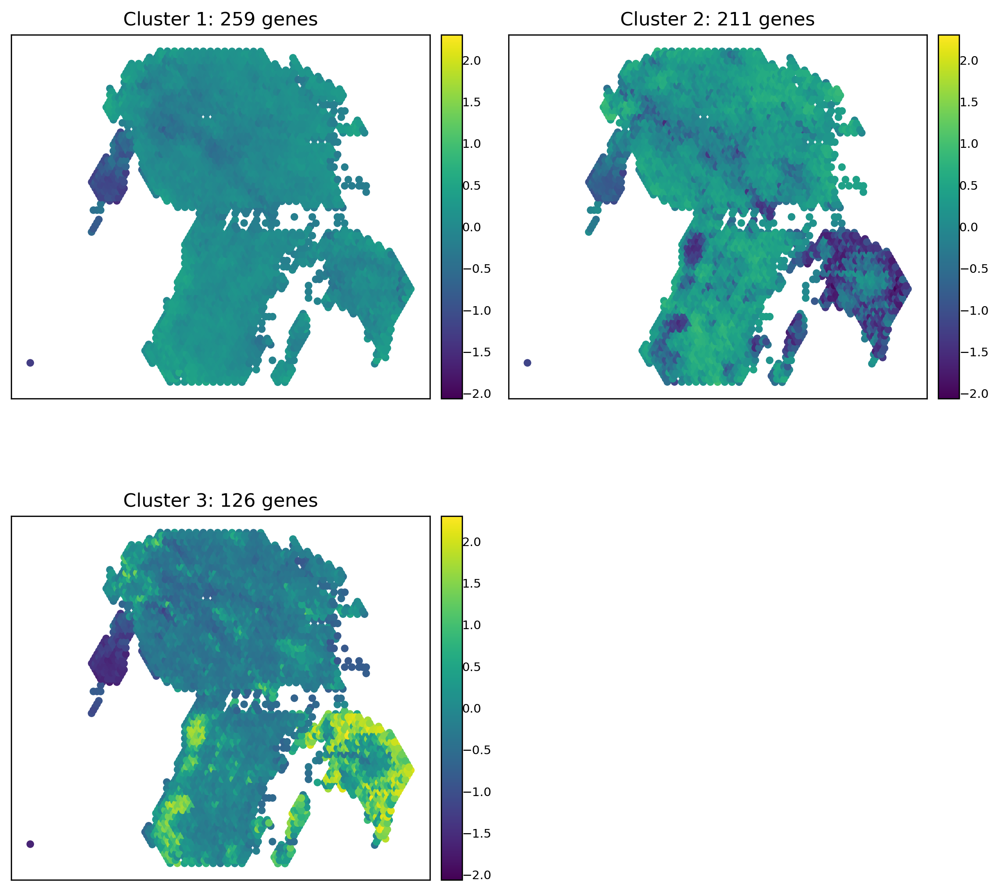

In [16]:
plot_clusters(gaussian_npc_genes)


## Comparison methods: shared NPC input

Run these cells after the NPC1-genes cells above. All methods use the same retained, standardized gene profiles and `SEED`; the original `.X` is unchanged. There is no additional expression transformation or feature selection (RSF and MEFISTO use float32).

SpatialDE AEH uses the corresponding squared-exponential length scale, `sqrt(1 / (2 * gamma))`, where `gamma` is SparseAEH's RBF parameter `l`. Its dense calculation can be expensive on all NPC locations. Gaussian **RSF**, from the NSF package, replaces Poisson NSF here because standardized values can be negative; it is not the nonnegative NSF model used in the other sections. RSF and MEFISTO return spatial factors and gene loadings, not AEH-style gene clusters.

The existing benchmark recorder measures model construction and fitting separately for each method; RSF also includes dataset preparation and inducing-point selection. Shared expression preprocessing, interpretation, plotting and file saving are excluded. Peak RAM is whole-notebook process RAM, including arrays and models retained from earlier cells, not isolated-method memory. Results are saved in a session-specific folder printed below.

In [17]:
NPC_GENE_FACTORS = gaussian_npc_genes.K
NPC_AEH_LENGTH_SCALE = np.sqrt(1 / (2 * gaussian_npc_genes.kernel.l))
NPC_GENE_INDUCING = min(500, npc_gene_input.shape[0])
NPC_RSF_S = 20

npc_gene_adata = ad.AnnData(
    X=npc_gene_input.copy(),
    obs=pd.DataFrame(index=npc_gene_standardized.index.copy()),
    var=pd.DataFrame(index=npc_gene_standardized.columns.copy())
)
npc_gene_adata.obsm['spatial'] = npc_spatial.copy()
npc_gene_parameters = {
    'method_seed': SEED, 'input_file': NPC_GENE_PATH,
    'expression_source': '.X', 'input_type': 'FineST-imputed gene expression',
    'preprocessing': 'near-constant filtering; gene-wise centering and scaling',
    'min_relative_sd': NPC_MIN_REL_SD, 'std_ddof': 0,
}
npc_gene_output = bench.output_dir / ('npc_genes_' + bench.session_id)
npc_gene_output.mkdir(parents=True, exist_ok=True)
print('NPC gene comparison results:', npc_gene_output)

NPC gene comparison results: /grp01/sbms_yhhuang/tianjie/AEH/benchmark_logs/npc_genes_20261028T012326Z_615576_0a7a5a6c


### SpatialDE AEH

Use `fit_patterns` on the already-standardized genes-by-locations matrix, avoiding the wrapper's repeated standardization and a separate SVG screen. All retained genes enter the mixture.

In [18]:
reset_seed()
with bench.run(
    method='SpatialDE AEH', dataset='NPC1_genes',
    scope='AEH model construction and fitting; excludes shared preprocessing, SVG detection, plotting and saving',
    parameters={**npc_gene_parameters, 'C': NPC_GENE_FACTORS,
                'l': NPC_AEH_LENGTH_SCALE, 'maxiter': 100,
                'delta_elbo_threshold': 1e-2, 'svg_selection': False},
    input_shape=npc_gene_input.shape, device='cpu'
) as bench_run:
    npc_aeh_elbo, npc_aeh_mean, npc_aeh_membership, npc_aeh_noise = SpatialDE.aeh.fit_patterns(
        npc_spatial, npc_gene_input.T, C=NPC_GENE_FACTORS,
        l=NPC_AEH_LENGTH_SCALE, maxiter=100, delta_elbo_threshold=1e-2, verbosity=1
    )
    bench_run.finish_timing()
    bench_run.details.update({'gene_names': npc_gene_standardized.columns.tolist(),
                              'final_elbo': float(npc_aeh_elbo)})

iter 0, ELBO: -3.16e+11
iter 1, ELBO: -1.63e+11, delta_ELBO: 1.53e+11
iter 2, ELBO: -1.63e+11, delta_ELBO: 3.38e+05
iter 3, ELBO: -1.63e+11, delta_ELBO: 1.54e+05
iter 4, ELBO: -1.63e+11, delta_ELBO: 5.13e+04
iter 5, ELBO: -1.63e+11, delta_ELBO: 9.39e+03
iter 6, ELBO: -1.63e+11, delta_ELBO: 5.77e+03
iter 7, ELBO: -1.63e+11, delta_ELBO: 2.18e+03
iter 8, ELBO: -1.63e+11, delta_ELBO: 7.45e+02
iter 9, ELBO: -1.63e+11, delta_ELBO: 2.52e+01
iter 10, ELBO: -1.63e+11, delta_ELBO: 2.63e+02
iter 11, ELBO: -1.63e+11, delta_ELBO: 3.11e+00
iter 12, ELBO: -1.63e+11, delta_ELBO: 8.06e+01
iter 13, ELBO: -1.63e+11, delta_ELBO: 2.31e+02
iter 14, ELBO: -1.63e+11, delta_ELBO: 1.36e+01
iter 15, ELBO: -1.63e+11, delta_ELBO: 1.48e-01
iter 16, ELBO: -1.63e+11, delta_ELBO: 3.75e+01
iter 17, ELBO: -1.63e+11, delta_ELBO: 2.46e+02
iter 18, ELBO: -1.63e+11, delta_ELBO: 5.04e+01
iter 19, ELBO: -1.63e+11, delta_ELBO: 2.39e+01
iter 20, ELBO: -1.63e+11, delta_ELBO: 2.49e+01
iter 21, ELBO: -1.63e+11, delta_ELBO: 1.84e-0

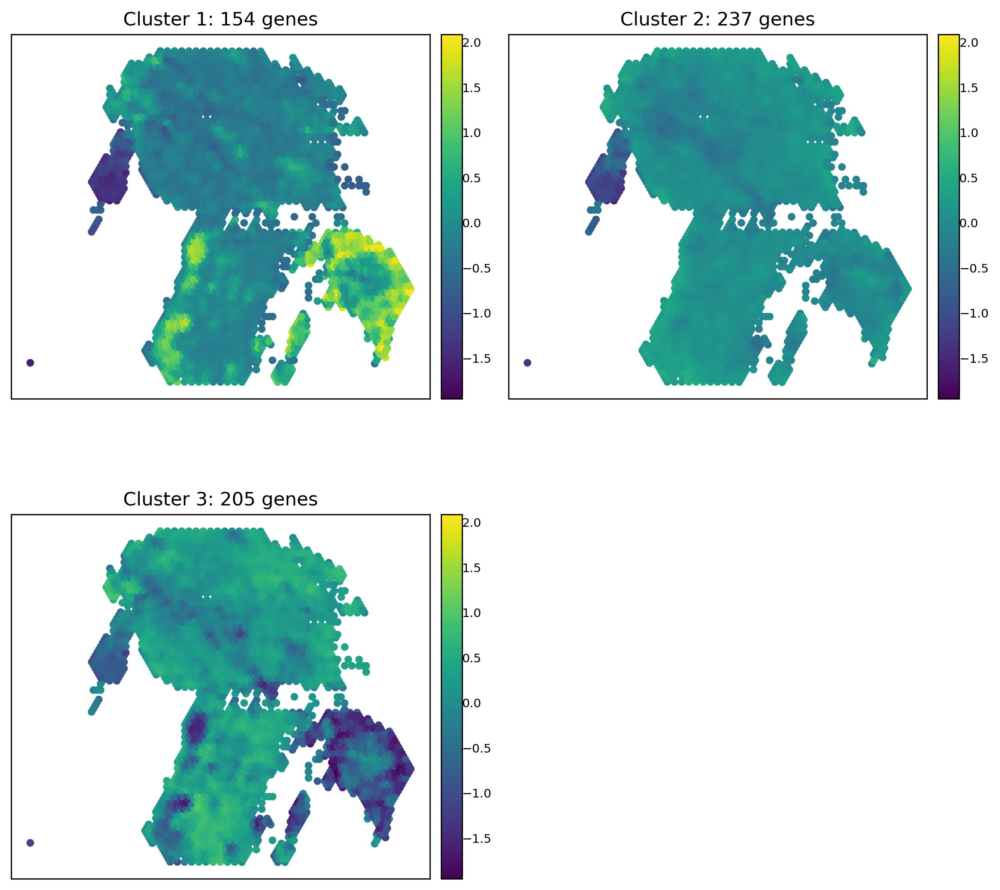

In [19]:
npc_aeh_patterns = pd.DataFrame({
    'g': npc_gene_standardized.columns,
    'pattern': npc_aeh_membership.argmax(axis=1),
    'membership': npc_aeh_membership.max(axis=1)
})
npc_aeh_patterns.to_csv(npc_gene_output / 'spatialde_aeh_genes.csv', index=False)
pd.DataFrame(npc_aeh_mean, index=npc_gene_standardized.index).to_csv(
    npc_gene_output / 'spatialde_aeh_patterns.csv')
plot_clusters(mean=np.asarray(npc_aeh_mean), spatial=npc_spatial,
              count=np.bincount(npc_aeh_patterns['pattern'], minlength=NPC_GENE_FACTORS),
              save=str(npc_gene_output / 'spatialde_aeh.png'))

### Gaussian RSF (NSF package)

Use Gaussian observations and unconstrained factors/loadings (`lik='gau', nonneg=False`), with constant size factors. The package rescales coordinates internally, not expression. Inducing points are selected on those same rescaled coordinates; plots retain the original coordinates. `NPC_RSF_S` controls Monte Carlo samples per training step, independently of the 100 interpretation samples.

In [ ]:
reset_seed()
with tf.device('/CPU:0'), bench.run(
    method='RSF (Gaussian)', dataset='NPC1_genes',
    scope='dataset preparation, inducing-point selection, model construction and fitting; excludes shared expression preprocessing, interpretation, plotting and saving',
    parameters={**npc_gene_parameters, 'factors': NPC_GENE_FACTORS,
                'inducing_points': NPC_GENE_INDUCING, 'kernel': 'MaternThreeHalves',
                'likelihood': 'gau', 'nonnegative': False, 'size_factors': 'constant',
                'coordinate_scaling': 'NSF rescale_spatial_coords, box_side=4',
                'training_samples': NPC_RSF_S, 'interpretation_samples': 100,
                'num_epochs': 5000, 'tol': 5e-5, 'status_freq': 50,
                'learning_rate': 0.01, 'length_scale_init': 0.1},
    input_shape=npc_gene_input.shape, device='cpu'
) as bench_run:
    npc_rsf_data, npc_rsf_val = preprocess.anndata_to_train_val(
        npc_gene_adata, train_frac=1.0, flip_yaxis=False, sz='constant'
    )
    npc_rsf_tf = preprocess.prepare_datasets_tf(npc_rsf_data, Dval=npc_rsf_val)
    npc_rsf_Z = misc.kmeans_inducing_pts(npc_rsf_data['X'], NPC_GENE_INDUCING)
    npc_rsf_fit = sf.SpatialFactorization(
        npc_rsf_data['Y'].shape[1], NPC_GENE_FACTORS, npc_rsf_Z,
        psd_kernel=tfk.MaternThreeHalves, nonneg=False, lik='gau', length_scale=0.1
    )
    npc_rsf_fit.init_loadings(npc_rsf_data['Y'], X=npc_rsf_data['X'], sz=npc_rsf_data['sz'])
    npc_rsf_trainer = training.ModelTrainer(npc_rsf_fit, lr=0.01)
    npc_rsf_trainer.train_model(*npc_rsf_tf, S=NPC_RSF_S,
                                num_epochs=5000, tol=5e-5, status_freq=50)
    bench_run.finish_timing()
    bench_run.details.update({'gene_names': npc_gene_standardized.columns.tolist(),
                              'actual_inducing_points': npc_rsf_Z.shape[0]})

In [ ]:
with tf.device('/CPU:0'):
    npc_rsf_result = postprocess.interpret_rsf(npc_rsf_fit, npc_rsf_data['X'], S=100)
pd.DataFrame(npc_rsf_result['factors'], index=npc_gene_standardized.index).to_csv(
    npc_gene_output / 'rsf_gaussian_factors.csv')
pd.DataFrame(npc_rsf_result['loadings'], index=npc_gene_standardized.columns).to_csv(
    npc_gene_output / 'rsf_gaussian_loadings.csv')
plot_clusters(mean=npc_rsf_result['factors'], spatial=npc_spatial,
              save=str(npc_gene_output / 'rsf_gaussian.png'))

### MEFISTO

Use a Gaussian likelihood and disable further expression centering/scaling. As in the earlier comparisons, fit three spatial factors (or `NPC_GENE_FACTORS`) using a sparse GP with up to 500 inducing points.

In [ ]:
reset_seed()
with bench.run(
    method='MEFISTO', dataset='NPC1_genes',
    scope='data ingestion, model construction and fitting; excludes shared expression preprocessing, extraction, plotting and saving',
    parameters={**npc_gene_parameters, 'factors': NPC_GENE_FACTORS,
                'inducing_points': NPC_GENE_INDUCING, 'sparseGP': True,
                'likelihood': 'gaussian', 'use_float32': True,
                'center_groups': False, 'scale_views': False, 'scale_groups': False,
                'scale_cov': False, 'start_opt': 10, 'opt_freq': 10,
                'iter': 1000, 'convergence_mode': 'fast', 'gpu_mode': False},
    input_shape=npc_gene_input.shape, device='cpu'
) as bench_run:
    npc_mefisto = entry_point()
    npc_mefisto.set_data_options(use_float32=True, center_groups=False,
                                 scale_views=False, scale_groups=False)
    npc_mefisto.set_data_from_anndata(npc_gene_adata.copy(), likelihoods=['gaussian'])
    npc_mefisto.set_model_options(factors=NPC_GENE_FACTORS)
    npc_mefisto.set_train_options(seed=SEED, gpu_mode=False, iter=1000, convergence_mode='fast')
    npc_mefisto.set_covariates([npc_spatial.copy()], covariates_names=['imagerow', 'imagecol'])
    npc_mefisto.set_smooth_options(sparseGP=True,
        frac_inducing=NPC_GENE_INDUCING / npc_gene_input.shape[0],
        scale_cov=False, start_opt=10, opt_freq=10)
    npc_mefisto.build()
    npc_mefisto.run()
    bench_run.finish_timing()
    bench_run.details['gene_names'] = npc_gene_standardized.columns.tolist()

In [ ]:
npc_mefisto_factors = npc_mefisto.model.nodes['Z'].getExpectation()
npc_mefisto_loadings = npc_mefisto.model.nodes['W'].getExpectation()[0]
npc_mefisto.save(str(npc_gene_output / 'mefisto_model.hdf5'))
pd.DataFrame(npc_mefisto_factors, index=npc_gene_standardized.index).to_csv(
    npc_gene_output / 'mefisto_factors.csv')
pd.DataFrame(npc_mefisto_loadings, index=npc_gene_standardized.columns).to_csv(
    npc_gene_output / 'mefisto_loadings.csv')
plot_clusters(mean=npc_mefisto_factors, spatial=npc_spatial,
              save=str(npc_gene_output / 'mefisto.png'))

### Full-covariance GEM

Run the updated SparseAEH fit and the shared comparison setup above first; the SpatialDE, RSF and MEFISTO fits are not prerequisites. This matched counterpart uses one group containing all locations (`group_size=N`, `d=0`), the same RBF covariance, processed input, saved initial parameters and GEM settings. No partition or conditional approximation remains. The covariance is still kernel-based, not an unrestricted estimated matrix.

This uses the existing Cholesky-based fitting path, not a cached spectral implementation. Repeated full factorizations during line search can be expensive; its runtime is not an optimized full-covariance baseline. Both fit timings include construction and fitting, exclude the separately recorded shared initialization, and exclude plotting/saving. Add the shared initialization time to each fit for end-to-end timing. Peak RAM is sampled whole-notebook process memory, not isolated-method memory.

ARI and NMI below measure agreement between gene assignments, not biological accuracy. Fit outputs, gene assignments, mean profiles and shared initialization are saved in `npc_gene_output`. A rerun replaces these files within the session; benchmark records remain append-only.


In [ ]:
reset_seed()
with bench.run(
    method='Full-covariance GEM', dataset='NPC1_genes',
    scope='model construction and GEM fitting; excludes file loading, dense conversion and preprocessing; shared initialization recorded separately',
    parameters={**NPC_GEM_PARAMETERS, 'group_size': len(npc_spatial), 'd': 0,
                'implementation': 'single-group Cholesky; no spectral cache'},
    input_shape=npc_gene_input.shape, device='cpu'
) as bench_run:
    gaussian_npc_full = MixedGaussian(
        npc_spatial, group_size=len(npc_spatial), d=0, **NPC_GEM_KERNEL
    )
    cluster_npc_full = gaussian_npc_full.run_cluster(
        npc_gene_input, NPC_GEM_K, **NPC_GEM_FIT,
        **{name: value.copy() for name, value in npc_gem_initial.items()}
    )
    bench_run.finish_timing()
    bench_run.details.update(sparseaeh_details(gaussian_npc_full))
    bench_run.details['gene_names'] = npc_gene_standardized.columns.tolist()


In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

npc_gem_agreement = pd.DataFrame([{
    'comparison': 'SparseAEH vs full-covariance GEM',
    'ARI': adjusted_rand_score(gaussian_npc_genes.labels, gaussian_npc_full.labels),
    'NMI': normalized_mutual_info_score(gaussian_npc_genes.labels, gaussian_npc_full.labels),
}])
npc_gem_agreement.to_csv(npc_gene_output / 'gem_agreement.csv', index=False)
pd.DataFrame({
    'gene': npc_gene_standardized.columns,
    'sparse_cluster': gaussian_npc_genes.labels,
    'full_covariance_cluster': gaussian_npc_full.labels,
}).to_csv(npc_gene_output / 'gem_gene_assignments.csv', index=False)
np.savez_compressed(npc_gene_output / 'gem_initialization.npz',
                    sampled_gene_indices=npc_gem_sample, **npc_gem_initial)
for name, model in [('sparse', gaussian_npc_genes), ('full_covariance', gaussian_npc_full)]:
    pd.DataFrame(model.mean, index=npc_gene_standardized.index).to_csv(
        npc_gene_output / (name + '_gem_means.csv'))
    np.savez_compressed(npc_gene_output / (name + '_gem_fit.npz'),
                        mean=model.mean, labels=model.labels, omega=model.omega,
                        pi=model.pi, sigma_sq=model.sigma_sq, delta=model.delta,
                        log_likelihood_history=model.log_likelihood_history)
plot_clusters(gaussian_npc_full, save=str(npc_gene_output / 'full_covariance_gem.png'))
print(npc_gem_agreement.to_string(index=False))


### Cell2location correspondence

Place `NPC_cell2location.csv` beside this notebook: the first column contains spot IDs matching the NPC expression table, and the six remaining columns contain the named cell-type profiles. Run from the `SparseAEH` directory. Values are used as supplied, without logging or conversion to proportions. Set `NPC_CELL2LOCATION_ESTIMATE` once the abundance/proportion/posterior summary is known. Reference rows are reordered by spot ID; missing or duplicated IDs are not matched by position.

For each method, compute the signed pattern-by-cell-type Pearson and Spearman correlations. With three patterns and six cell types these are 3-by-6 heatmaps. The descriptive coverage score is

$$S_{\mathrm{coverage}}=\frac{1}{T}\sum_{t=1}^{T}\max\left(0,\max_k r_{kt}\right),\qquad T=6.$$

The same pattern may match several cell types; there is no one-to-one assignment. Negative correlations contribute zero to coverage but remain visible in the heatmap and signed-best column. Constant profiles have undefined correlations (blank/NA), not zero correlations. Constant patterns are excluded from the maximum; if a cell type has no defined correlation, its coverage and the overall mean are NA rather than averaging over fewer types.

SparseAEH is enabled below; uncomment other methods only after running their NPC gene fits and output cells on the same input. Compare coverage at the same number of patterns. Gaussian RSF and MEFISTO factors have arbitrary signs: the optional helper orients each factor so its largest-absolute gene loading is positive, independently of the reference. This is a convention, not a biological guarantee; their positive-coverage scores depend on that convention. AEH cluster means retain their original signs.

These are reference-map correspondence scores, not clustering accuracy or independent ground truth. The maximum can favor larger pattern counts, and correlated cell-type maps can share the same best pattern. No significance tests are performed because ordinary independent-spot tests ignore spatial autocorrelation. The cell-type correlation heatmaps help show shared reference structure. CSV tables, aligned reference profiles, settings, PNGs and PDFs are saved below the existing session output directory.


In [ ]:
from pathlib import Path
import json
import matplotlib.pyplot as plt

NPC_CELL2LOCATION_CSV = Path('NPC_cell2location.csv')
NPC_CELL2LOCATION_ESTIMATE = 'unspecified'  # e.g. abundance posterior mean, proportion, or q05
npc_celltype_reference = pd.read_csv(
    NPC_CELL2LOCATION_CSV, index_col=0, dtype=str
).apply(pd.to_numeric)
npc_celltype_reference.index = npc_celltype_reference.index.astype(str)
npc_celltype_spots = npc_gene_standardized.index.astype(str)
if not npc_celltype_reference.index.is_unique or not npc_celltype_spots.is_unique:
    raise ValueError('Cell2location and NPC spot IDs must be unique.')
if npc_celltype_reference.shape[1] != 6:
    raise ValueError('Expected six named cell-type columns after the spot-ID column.')
missing = npc_celltype_spots.difference(npc_celltype_reference.index)
if len(missing):
    raise ValueError(f'{len(missing)} NPC spots are missing from the cell2location CSV.')
npc_celltype_reference = npc_celltype_reference.loc[npc_celltype_spots].copy()
if not np.isfinite(npc_celltype_reference.to_numpy()).all():
    raise ValueError('Cell2location profiles must contain finite numeric values.')
npc_celltype_output = bench.output_dir / ('npc_genes_' + bench.session_id) / 'cell2location'
npc_celltype_output.mkdir(parents=True, exist_ok=True)
print('Aligned reference:', npc_celltype_reference.shape, '| Results:', npc_celltype_output)


In [ ]:
def npc_orient_factors(factors, loadings):
    # A single sign per factor, chosen without looking at cell2location.
    factors, loadings = np.asarray(factors), np.asarray(loadings)
    anchors = loadings[np.argmax(np.abs(loadings), axis=0), np.arange(loadings.shape[1])]
    return factors * np.where(anchors < 0, -1.0, 1.0)


def npc_profile_correlations(patterns, reference, metric='pearson'):
    patterns = np.asarray(patterns, dtype=float)
    if patterns.ndim != 2 or patterns.shape[0] != len(reference) or patterns.shape[1] == 0:
        raise ValueError('Patterns must be a locations-by-patterns matrix matching the NPC input.')
    if not np.isfinite(patterns).all():
        raise ValueError('Pattern profiles must contain finite values.')
    x, y = pd.DataFrame(patterns), reference.reset_index(drop=True)
    if metric == 'spearman':
        x, y = x.rank(method='average'), y.rank(method='average')
    elif metric != 'pearson':
        raise ValueError('Use pearson or spearman.')
    x, y = x.to_numpy(dtype=float), y.to_numpy(dtype=float)
    varying = np.outer(np.ptp(x, axis=0) > 0, np.ptp(y, axis=0) > 0)
    x, y = x - x.mean(axis=0), y - y.mean(axis=0)
    denom = np.outer(np.linalg.norm(x, axis=0), np.linalg.norm(y, axis=0))
    corr = np.divide(x.T @ y, denom, out=np.full(denom.shape, np.nan), where=(denom > 0) & varying)
    return pd.DataFrame(np.clip(corr, -1, 1),
                        index=[f'Pattern {k}' for k in range(patterns.shape[1])],
                        columns=reference.columns)


def npc_coverage_table(correlations):
    best = correlations.max(axis=0)
    winners = pd.Series(index=correlations.columns, dtype=object)
    positive = best > 0
    winners.loc[positive] = correlations.loc[:, positive].idxmax(axis=0)
    return pd.DataFrame({
        'cell_type': correlations.columns,
        'best_positive_pattern': winners.to_numpy(),
        'best_signed_correlation': best.to_numpy(),
        'positive_coverage': best.clip(lower=0).to_numpy(),
        'defined_patterns': correlations.notna().sum(axis=0).to_numpy(),
    })


npc_celltype_patterns = {
    'SparseAEH': gaussian_npc_genes.mean,
    # 'Full-covariance GEM': gaussian_npc_full.mean,
    # 'SpatialDE AEH': npc_aeh_mean,
    # 'RSF (Gaussian)': npc_orient_factors(npc_rsf_result['factors'], npc_rsf_result['loadings']),
    # 'MEFISTO': npc_orient_factors(npc_mefisto_factors, npc_mefisto_loadings),
}
npc_celltype_correlations = {}
npc_celltype_tables, npc_celltype_scores = [], []
for method, patterns in npc_celltype_patterns.items():
    for metric in ('pearson', 'spearman'):
        correlations = npc_profile_correlations(patterns, npc_celltype_reference, metric)
        npc_celltype_correlations[method, metric] = correlations
        table = npc_coverage_table(correlations)
        table.insert(0, 'metric', metric)
        table.insert(0, 'method', method)
        npc_celltype_tables.append(table)
        npc_celltype_scores.append({
            'method': method, 'metric': metric, 'patterns': correlations.shape[0],
            'cell_types': correlations.shape[1], 'locations': len(npc_celltype_reference),
            'defined_cell_types': int(table['positive_coverage'].notna().sum()),
            'mean_positive_coverage': table['positive_coverage'].mean(skipna=False),
        })
npc_celltype_per_type = pd.concat(npc_celltype_tables, ignore_index=True)
npc_celltype_summary = pd.DataFrame(npc_celltype_scores)
npc_celltype_per_type.to_csv(npc_celltype_output / 'coverage_per_cell_type.csv', index=False)
npc_celltype_summary.to_csv(npc_celltype_output / 'coverage_summary.csv', index=False)
npc_celltype_reference.to_csv(npc_celltype_output / 'aligned_reference.csv')
pd.concat(npc_celltype_correlations, names=['method', 'metric', 'pattern']).to_csv(
    npc_celltype_output / 'pattern_celltype_correlations.csv')
for metric in ('pearson', 'spearman'):
    npc_celltype_reference.corr(method=metric).to_csv(
        npc_celltype_output / ('reference_' + metric + '_correlations.csv'))
with (npc_celltype_output / 'settings.json').open('w') as handle:
    json.dump({
        'reference_file': str(NPC_CELL2LOCATION_CSV.resolve()),
        'reference_estimate': NPC_CELL2LOCATION_ESTIMATE,
        'reference_transform': 'none', 'spot_alignment': 'exact IDs in NPC input order',
        'score': 'mean across cell types of max(0, max signed pattern correlation)',
        'undefined_policy': 'exclude constant patterns; undefined cell-type coverage makes mean NA',
        'factor_orientation': 'largest-absolute gene loading positive; no reference-based sign selection',
        'methods': list(npc_celltype_patterns), 'cell_types': npc_celltype_reference.columns.tolist(),
        'interpretation': 'descriptive correspondence; not biological accuracy or significance',
    }, handle, indent=2)
print(npc_celltype_summary.to_string(index=False))


In [ ]:
def npc_correlation_heatmap(ax, table, title):
    cmap = plt.get_cmap('RdBu_r').copy()
    cmap.set_bad('#eeeeee')
    image = ax.imshow(table.to_numpy(), vmin=-1, vmax=1, cmap=cmap, aspect='auto')
    ax.set_xticks(np.arange(table.shape[1]), labels=table.columns, rotation=45, ha='right')
    ax.set_yticks(np.arange(table.shape[0]), labels=table.index)
    ax.set_title(title, fontsize=12)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            value = table.iloc[i, j]
            ax.text(j, i, f'{value:.2f}' if np.isfinite(value) else 'NA',
                    ha='center', va='center', fontsize=9,
                    color='white' if np.isfinite(value) and abs(value) > 0.6 else 'black')
    return image


for metric in ('pearson', 'spearman'):
    ncols = min(2, len(npc_celltype_patterns))
    nrows = (len(npc_celltype_patterns) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(8 * ncols, 5 * nrows),
                             squeeze=False, layout='constrained')
    for ax, method in zip(axes.flat, npc_celltype_patterns):
        image = npc_correlation_heatmap(
            ax, npc_celltype_correlations[method, metric], method + ' | ' + metric.title())
    for ax in list(axes.flat)[len(npc_celltype_patterns):]:
        ax.set_visible(False)
    fig.colorbar(image, ax=list(axes.flat)[:len(npc_celltype_patterns)], label='Signed correlation')
    for extension in ('png', 'pdf'):
        fig.savefig(npc_celltype_output / ('pattern_celltype_' + metric + '.' + extension),
                    dpi=200, bbox_inches='tight')
    plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), layout='constrained')
for ax, metric in zip(axes, ('pearson', 'spearman')):
    image = npc_correlation_heatmap(ax, npc_celltype_reference.corr(method=metric),
                                    'Cell-type reference | ' + metric.title())
fig.colorbar(image, ax=list(axes), label='Signed correlation')
for extension in ('png', 'pdf'):
    fig.savefig(npc_celltype_output / ('reference_correlations.' + extension), dpi=200, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), layout='constrained')
for ax, metric in zip(axes, ('pearson', 'spearman')):
    selected = npc_celltype_per_type[npc_celltype_per_type['metric'] == metric]
    values = selected.pivot(index='cell_type', columns='method', values='positive_coverage')
    values = values.reindex(index=npc_celltype_reference.columns, columns=list(npc_celltype_patterns))
    values.plot.bar(ax=ax, rot=45, width=0.8)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Best-positive correlation')
    ax.set_xlabel('')
    ax.set_title(metric.title() + ' cell-type coverage', fontsize=12)
    plt.setp(ax.get_xticklabels(), ha='right')
    for i, row in enumerate(values.to_numpy()):
        for j, value in enumerate(row):
            if not np.isfinite(value):
                ax.text(i - 0.4 + (j + 0.5) * 0.8 / values.shape[1], 0.02, 'NA',
                        ha='center', va='bottom', rotation=90, fontsize=8)
for extension in ('png', 'pdf'):
    fig.savefig(npc_celltype_output / ('coverage_per_cell_type.' + extension), dpi=200, bbox_inches='tight')
plt.show()


# NPC1-ligand receptor pair

In [6]:
spot_diameter_fullres = 127.8358082731091
l = spot_diameter_fullres
cutoff = 0.001

single_cell = False
n_nearest_neighbors = 6 
n_neighbors = None, 
n_neighbors = n_nearest_neighbors * 31

l = spot_diameter_fullres
cutoff = 0.001 
n_neighbors=None  
n_nearest_neighbors=6
single_cell=False


## large neighborhood for W (5 layers)
from sklearn.neighbors import NearestNeighbors
def _Euclidean_to_RBF(X, l, singlecell=single_cell):
    """Convert Euclidean distance to RBF distance"""
    from scipy.sparse import issparse
    if issparse:
        rbf_d = X
        rbf_d[X.nonzero()] = np.exp(-X[X.nonzero()].A**2 / (2 * l ** 2))
    else:
        rbf_d = np.exp(- X**2 / (2 * l ** 2))
    # At single-cell resolution, no within-spot communications
    if singlecell:
        np.fill_diagonal(rbf_d, 0)
    else:
        rbf_d.setdiag(np.exp(-X.diagonal()**2 / (2 * l ** 2)))
    return rbf_d


adata_impt_all.uns['single_cell'] = single_cell
if isinstance(adata_impt_all.obsm['spatial'], pd.DataFrame):
    X_loc = adata_impt_all.obsm['spatial'].values
else:
    X_loc = adata_impt_all.obsm['spatial']

if n_neighbors is None:
    n_neighbors = n_nearest_neighbors * 31


## large neighborhood for W (5 layers)
nnbrs = NearestNeighbors(
    n_neighbors=n_neighbors,
    algorithm='ball_tree', 
    metric='euclidean'
).fit(X_loc)
nbr_d = nnbrs.kneighbors_graph(X_loc, mode='distance')
rbf_d = _Euclidean_to_RBF(nbr_d, l, single_cell)


## small neighborhood for RBF
nnbrs0 = NearestNeighbors(
    n_neighbors=n_nearest_neighbors, 
    algorithm='ball_tree', 
    metric='euclidean'
).fit(X_loc)
nbr_d0 = nnbrs0.kneighbors_graph(X_loc, mode='distance')
rbf_d0 = _Euclidean_to_RBF(nbr_d0, l, single_cell)


if cutoff:
    nonzero_mask = np.array(rbf_d[rbf_d.nonzero()] < cutoff)[0]
    rows = rbf_d.nonzero()[0][nonzero_mask]
    cols = rbf_d.nonzero()[1][nonzero_mask]
    rbf_d[rows, cols] = 0

adata_impt_all.obsp['weight'] = rbf_d * adata_impt_all.shape[0] / rbf_d.sum()
adata_impt_all.obsp['nearest_neighbors'] = rbf_d0 * adata_impt_all.shape[0] / rbf_d0.sum()

In [7]:
sdm.extract_lr(adata_impt_all, 'human', min_cell=3)      # find overlapping LRs from CellChatDB
print(adata_impt_all)

AnnData object with n_obs × n_vars = 5039 × 596
    obs: 'x', 'y'
    uns: 'geneInter', 'local_stat', 'local_z', 'local_z_p', 'selected_spots', 'single_cell', 'mean', 'ligand', 'receptor', 'num_pairs'
    obsm: 'spatial'
    obsp: 'nearest_neighbors', 'weight'


In [8]:
reset_seed()
sdm.spatialdm_global(adata_impt_all, n_perm=1000, specified_ind=None, method='z-score', nproc=1)     # global Moran selection
sdm.sig_pairs(adata_impt_all, method='z-score', fdr=True, threshold=0.1)     # select significant pairs

In [9]:
reset_seed()
with bench.run(
    method='SpatialDM', dataset='NPC_LR_preprocessing',
    scope='local test and significance selection',
    parameters={'method_seed': SEED, 'n_perm': 1000, 'method': 'z-score', 'nproc': 1, 'fdr': False, 'threshold': 0.1},
    input_shape=adata_impt_all.X.shape, device='cpu'
) as bench_run:
    adata_impt_all.raw = adata_impt_all

    import time
    start = time.perf_counter()
    sdm.spatialdm_local(adata_impt_all, n_perm=1000, method='z-score', specified_ind=None, nproc=1)     # local spot selection
    sdm.sig_spots(adata_impt_all, method='z-score', fdr=False, threshold=0.1)     # significant local spots
    spatialdm_time = time.perf_counter() - start
    bench_run.finish_timing(spatialdm_time)
    print("%.3f seconds" % spatialdm_time)

3.156 seconds


In [10]:
print(adata_impt_all)
adata_impt_all.uns["local_z_p"]

AnnData object with n_obs × n_vars = 5039 × 596
    obs: 'x', 'y'
    uns: 'geneInter', 'local_stat', 'local_z', 'local_z_p', 'selected_spots', 'single_cell', 'mean', 'ligand', 'receptor', 'num_pairs', 'global_I', 'global_stat', 'global_res'
    obsm: 'spatial'
    obsp: 'nearest_neighbors', 'weight'


,0,1,2,3,4,5,6,7,8,9,...,5029,5030,5031,5032,5033,5034,5035,5036,5037,5038
EFNA5_EPHB2,0.812734,1.000000,1.000000,1.000000,1.000000,0.889804,1.000000,1.000000,1.000000,1.000000,...,0.358390,1.000000,1.000000,0.612942,0.604228,1.000000,0.504169,0.586477,0.494672,1.000000
EFNB1_EPHA4,1.000000,0.475286,0.999987,0.461302,0.468892,0.512731,0.750120,0.960887,1.000000,1.000000,...,1.000000,0.553294,0.588101,0.535898,0.231551,0.405988,0.570580,0.565335,0.596308,0.628285
EFNB1_EPHB1,1.000000,0.697025,0.408778,0.451858,0.676784,0.638709,0.553805,1.000000,1.000000,0.641895,...,1.000000,0.520049,0.752744,0.301209,0.117563,0.308463,0.149040,0.402738,0.158178,0.021182
EFNB1_EPHB2,1.000000,0.585721,1.000000,0.460501,0.689316,0.039573,1.000000,1.000000,1.000000,1.000000,...,0.529120,0.480523,1.000000,0.431892,0.236407,0.521786,0.492014,0.401582,0.510983,0.664289
EFNB1_EPHB3,1.000000,0.600598,1.000000,0.587939,0.925723,0.579293,0.579617,1.000000,1.000000,1.000000,...,0.525378,0.484624,1.000000,0.553284,0.681660,0.525871,0.314680,0.380428,0.799997,0.650086
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CCL3_CCR5,1.000000,1.000000,1.000000,1.000000,0.738358,0.581517,1.000000,0.554348,0.970124,1.000000,...,0.032998,0.555073,0.570042,0.613510,0.512416,0.517058,1.000000,1.000000,0.490398,1.000000
CCL5_CCR5,1.000000,0.679945,1.000000,1.000000,0.916419,0.563568,0.521150,0.511465,0.023366,0.537434,...,0.437113,0.713286,0.811502,0.779320,0.445735,0.486822,0.554086,1.000000,1.000000,1.000000
CCL4_CCR5,1.000000,1.000000,1.000000,1.000000,0.925827,0.606581,1.000000,0.468196,0.000412,0.590434,...,0.264310,0.668238,0.844387,0.927276,0.359887,0.452005,0.551847,1.000000,1.000000,0.485147
CXCL1_ACKR1,0.538190,1.000000,0.295192,0.647770,1.000000,0.482652,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,0.495441,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [11]:
bin_spots = (1-adata_impt_all.uns["local_z_p"])[adata_impt_all.uns['local_stat']['n_spots']>2]
Y = bin_spots.to_numpy()

In [12]:
reset_seed()
with bench.run(
    method='SparseAEH', dataset='NPC_LR_profiles',
    scope='model construction and fitting',
    parameters={'method_seed': SEED, 'internal_kmeans_random_state': 0, 'group_size': 16, 'd': 30, 'l': 1e-5, 'K': 3, 'max_iter': 50, 'threshold': 5e-2},
    input_shape=Y.T.shape, device='cpu'
) as bench_run:
    gaussian_1 = MixedGaussian(adata_impt_all.obsm['spatial'],group_size=16,d=30,l=1e-5)
    cluster_1 = gaussian_1.run_cluster(Y.T,3,iter=50,init_mean='k_means') 
    bench_run.finish_timing()
    bench_run.details.update(sparseaeh_details(gaussian_1))

Iteration 0
updating variance
Iteration 1


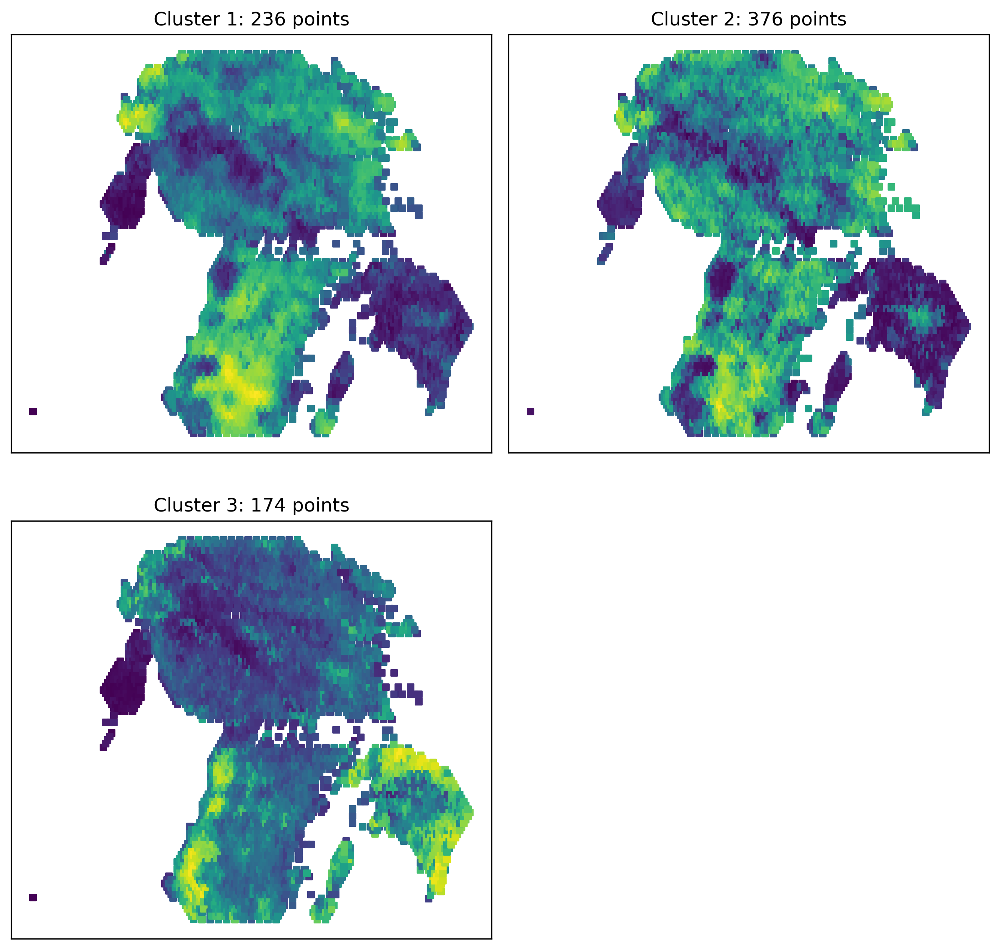

In [14]:
plot_clusters_1(gaussian_1)

# Visium HD - genes

/home/u3553426/.conda/envs/SparseAEH/lib/python3.9/site-packages/torch/cuda/__init__.py:138: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 302: Error loading CUDA libraries. GPU will not be used. (Triggered internally at ../c10/cuda/CUDAFunctions.cpp:108.)
  return torch._C._cuda_getDeviceCount() > 0


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
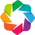

100%|██████████| 52.4M/52.4M [00:06<00:00, 8.62MB/s]


AnnData object with n_obs × n_vars = 136954 × 862
    obs: 'array_row', 'array_col'
    obsm: 'spatial'


In [22]:
from FineST.utils import *        
from FineST.datasets import dataset

#adata_impt_all = dataset.CRC_FineST()
adata_impt_all = dataset.CRC_Original()
adata_impt_all.obsm['spatial'] = np.column_stack((np.array(adata_impt_all.obs['array_row']), np.array(adata_impt_all.obs['array_col'])))
print(adata_impt_all)

In [23]:
reset_seed()
with bench.run(
    method='SparseAEH', dataset='FineST_CRC_Original',
    scope='model construction and fitting',
    parameters={'method_seed': SEED, 'internal_kmeans_random_state': 0, 'group_size': 16, 'd': 30, 'l': 1e-5, 'K': 6, 'max_iter': 50, 'threshold': 5e-2},
    input_shape=adata_impt_all.X.shape, device='cpu'
) as bench_run:
    gaussian_2 = MixedGaussian(adata_impt_all.obsm['spatial'],group_size=16,d=30,l=1e-5)
    cluster_2 = gaussian_2.run_cluster(adata_impt_all.X.toarray(),6,iter=50) 
    bench_run.finish_timing()
    bench_run.details.update(sparseaeh_details(gaussian_2))

Iteration 0
updating variance
Iteration 1
Iteration 2
Iteration 3
[-2.63510155e-08 -1.80809689e-15 -7.99924575e-16 -5.78713513e-16
 -4.94248322e-16 -2.84133826e-16 -2.29281629e-16 -2.18582473e-16
 -1.56746828e-16 -1.12081462e-16 -6.11156032e-17 -7.54498804e-19
  1.02484684e-16  1.83767773e-16  1.96187566e-16  2.57684657e-16
  3.71414475e-16  5.68742236e-16  8.02715511e-16  1.54074991e-15
  1.99387649e-15  2.61147627e-15  1.48466156e-14  2.33582692e-14
  1.63970828e-13  1.32491377e-11  7.42315585e-11  2.80227992e-09
  5.90706316e-06  6.54922442e-03]
[-4.40969968e-09 -1.90506962e-13 -9.97303200e-15 -3.63489563e-15
 -1.91262313e-15 -6.64924159e-16 -1.01468230e-16  9.01851400e-17
  1.33663066e-16  2.43426995e-16  4.59201827e-16  1.01872281e-15
  1.92496561e-15  2.28587764e-15  5.52042806e-15  9.37183730e-15
  7.16305369e-12  7.68814308e-10]
[-1.19196493e-05 -6.84899747e-13 -9.73678360e-15 -2.55209982e-15
 -1.72329150e-15 -1.43081711e-15 -1.13668035e-15 -8.52165972e-16
 -8.19750236e-16 -2.2

/grp01/sbms_yhhuang/tianjie/AEH/SparseAEH/utils.py:49: RuntimeWarning: divide by zero encountered in log
  ll[:,k] += np.log(det)
/grp01/sbms_yhhuang/tianjie/AEH/SparseAEH/utils.py:49: RuntimeWarning: invalid value encountered in log
  ll[:,k] += np.log(det)


[-3.47696835e-12 -1.43991644e-13 -6.76843372e-14 -5.12246305e-14
 -3.75538121e-14 -2.66785970e-14 -1.15869508e-14 -1.00349078e-14
 -5.31498255e-15 -1.22414601e-15 -2.23822725e-16  4.93294226e-15
  6.49844656e-15  1.14176782e-14  1.95806264e-14  2.12009342e-14
  4.23999934e-14  5.35012726e-14  8.50214115e-14  2.27731864e-13]
[-9.39029788e-12 -3.07132675e-14 -1.47900179e-14 -1.00815501e-14
 -6.92113784e-15 -4.93007470e-15 -3.83822325e-15 -2.50868471e-15
 -1.72732963e-15 -1.37131739e-15 -6.15750533e-16  7.49111272e-16
  1.10723722e-15  2.07335823e-15  2.22606260e-15  3.48956035e-15
  5.50492742e-15  7.35143031e-15  7.95436726e-15  8.58592743e-15
  1.05604158e-14  1.35895882e-14  1.73582292e-14  2.94687683e-14
  6.80961129e-14]
[-1.02823983e-13 -5.36398393e-14 -2.17926688e-14 -8.89689143e-15
 -8.34457813e-15 -7.23011910e-15 -5.54237752e-15 -4.21495432e-15
 -3.15907280e-15 -2.08336143e-15 -1.67092396e-15  4.93125310e-16
  1.84735479e-15  2.54610755e-15  3.15523257e-15  3.50163086e-15
  5.03

/grp01/sbms_yhhuang/tianjie/AEH/SparseAEH/base.py:395: RuntimeWarning: divide by zero encountered in scalar divide
  self.omega[g,k] = self.pi[k]/np.sum(self.pi * _pexp((ll[g]-ll[g][k]))) + 1e-3/self.G
/grp01/sbms_yhhuang/tianjie/AEH/SparseAEH/base.py:258: RuntimeWarning: invalid value encountered in matmul
  new_mean[:,k:(k+1)] = self.Y @ omega[:,k:(k+1)] / np.sum(omega[:,k])


Iteration 4


LinAlgError: Eigenvalues did not converge

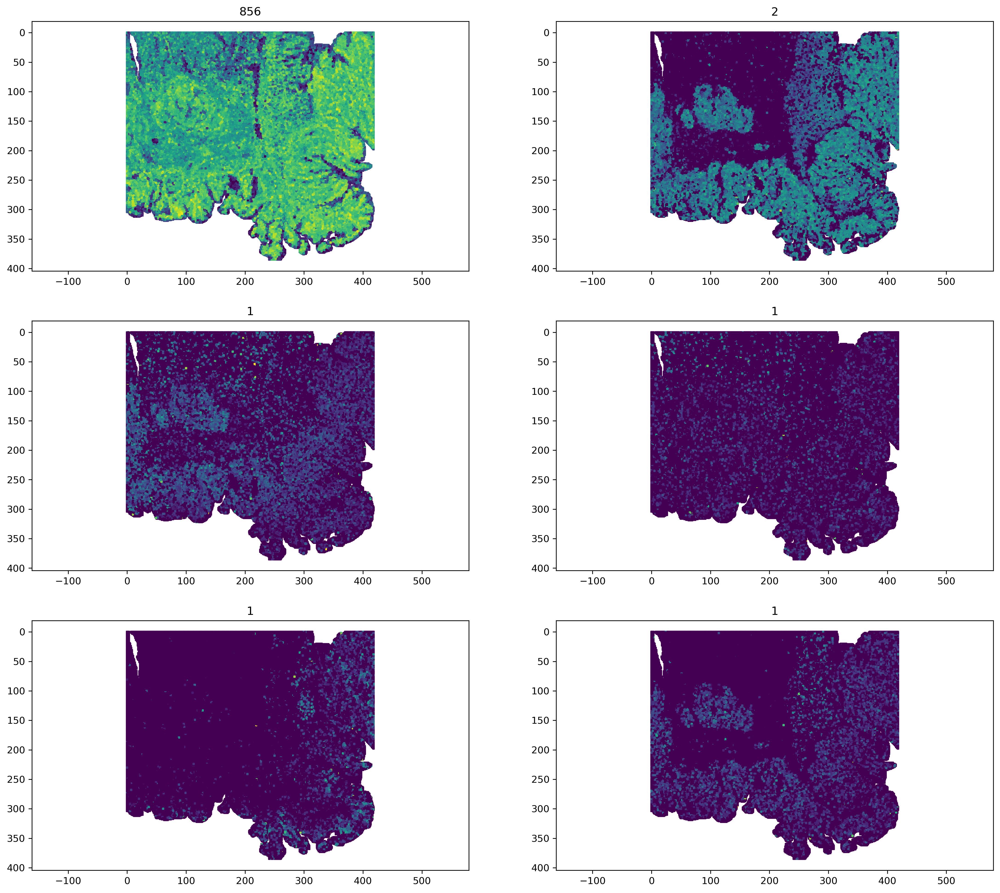

In [22]:
plot_clusters(gaussian_2,s=2)

# Visium HD - ligand receptor pair

In [ ]:
spot_diameter_fullres = 130    
l = spot_diameter_fullres
cutoff = 0.001
n_nearest_neighbors=6
single_cell=False
# n_neighbors=None  
n_neighbors = n_nearest_neighbors * 31

## large neighborhood for W (5 layers)
from sklearn.neighbors import NearestNeighbors
def _Euclidean_to_RBF(X, l, singlecell=single_cell):
    """Convert Euclidean distance to RBF distance"""
    from scipy.sparse import issparse
    if issparse:
        rbf_d = X
        rbf_d[X.nonzero()] = np.exp(-X[X.nonzero()].A**2 / (2 * l ** 2))
    else:
        rbf_d = np.exp(- X**2 / (2 * l ** 2))
    
    # At single-cell resolution, no within-spot communications
    if singlecell:
        np.fill_diagonal(rbf_d, 0)
    else:
        rbf_d.setdiag(np.exp(-X.diagonal()**2 / (2 * l ** 2)))

    return rbf_d


adata_impt_all.uns['single_cell'] = single_cell
if isinstance(adata_impt_all.obsm['spatial'], pd.DataFrame):
    X_loc = adata_impt_all.obsm['spatial'].values
else:
    X_loc = adata_impt_all.obsm['spatial']

if n_neighbors is None:
    n_neighbors = n_nearest_neighbors * 31


## large neighborhood for W (5 layers)
nnbrs = NearestNeighbors(
    n_neighbors=n_neighbors,
    algorithm='ball_tree', 
    metric='euclidean'
).fit(X_loc)
nbr_d = nnbrs.kneighbors_graph(X_loc, mode='distance')
rbf_d = _Euclidean_to_RBF(nbr_d, l, single_cell)


## small neighborhood for RBF
nnbrs0 = NearestNeighbors(
    n_neighbors=n_nearest_neighbors, 
    algorithm='ball_tree', 
    metric='euclidean'
).fit(X_loc)
nbr_d0 = nnbrs0.kneighbors_graph(X_loc, mode='distance')
rbf_d0 = _Euclidean_to_RBF(nbr_d0, l, single_cell)


if cutoff:
    nonzero_mask = np.array(rbf_d[rbf_d.nonzero()] < cutoff)[0]
    rows = rbf_d.nonzero()[0][nonzero_mask]
    cols = rbf_d.nonzero()[1][nonzero_mask]
    rbf_d[rows, cols] = 0


adata_impt_all.obsp['weight'] = rbf_d * adata_impt_all.shape[0] / rbf_d.sum()
adata_impt_all.obsp['nearest_neighbors'] = rbf_d0 * adata_impt_all.shape[0] / rbf_d0.sum()

In [ ]:
sdm.extract_lr(adata_impt_all, 'human', min_cell=3)      # find overlapping LRs from CellChatDB
print(adata_impt_all)

In [ ]:
reset_seed()
sdm.spatialdm_global(adata_impt_all, n_perm=1000, specified_ind=None, method='z-score', nproc=1)     # global Moran selection
sdm.sig_pairs(adata_impt_all, method='z-score', fdr=True, threshold=0.1)     # select significant pairs

In [ ]:
reset_seed()
sdm.spatialdm_local(adata_impt_all, n_perm=1000, method='z-score', specified_ind=None, nproc=1)     # local spot selection
sdm.sig_spots(adata_impt_all, method='z-score', fdr=False, threshold=0.1)     # significant local spots

In [ ]:
bin_spots = (1-adata_impt_all.uns["local_z_p"])[adata_impt_all.uns['local_stat']['n_spots']>2]
X = adata_impt_all.obsm['spatial']
exp_tab = bin_spots.transpose()

In [ ]:
reset_seed()
with bench.run(
    method='SparseAEH', dataset='FineST_CRC_LR_profiles',
    scope='model construction and fitting',
    parameters={'method_seed': SEED, 'internal_kmeans_random_state': 0, 'group_size': 16, 'd': 5, 'l': 0.01, 'K': 6, 'max_iter': 50, 'threshold': 5e-2},
    input_shape=exp_tab.shape, device='cpu'
) as bench_run:
    gaussian_3 = MixedGaussian(spatial = adata_impt_all.obsm['spatial'],
                             cov=None, group_size=16, d=5, kernel='rbf', l=0.01)
    gaussian_3.run_cluster(np.array(exp_tab), 6, iter=50)
    bench_run.finish_timing()
    bench_run.details.update(sparseaeh_details(gaussian_3))

# Embryobeta cells

In [8]:
X = pd.read_csv('embryoBeta_X.csv', index_col = 0)
X.head()

,bE17.5_1_01,bE17.5_1_02,bE17.5_1_03,bE17.5_1_04,bE17.5_1_05,bE17.5_2_01,bE17.5_2_02,bE17.5_2_03,bE17.5_2_04,bE17.5_2_05,...,bP0_2_30,bP0_2_31,bP9_2_24,bP9_2_25,bP9_2_26,bP9_4_13,bP15_1_21,bP15_1_22,bP60_1_40,bP60_3_30
Symbol,,,,,,,,,,,,,,,,,,,,,
Cdc45,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,27.61,0.00,...,0.00,0.00,20.62,0.00,0.00,67.31,53.64,0.0,0.00,0.00
H19,0.00,0.00,0.00,0.00,0.00,0.00,0.40,0.00,0.00,0.85,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00
Scml2,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,8.42,0.0,0.00,0.00
Narf,18.44,47.67,16.61,6.71,37.55,25.99,15.69,17.02,13.69,0.00,...,38.78,0.00,0.00,6.34,3.59,7.88,0.00,0.0,14.64,30.85
Klf6,0.26,6.11,3.07,0.96,21.38,6.07,20.44,9.39,5.08,7.83,...,22.68,46.41,8.06,9.61,7.48,7.11,14.27,13.6,0.00,14.11


In [9]:
Y = pd.read_csv('embryoBeta_Y.csv', index_col = 0)
Y.head()

,time
bE17.5_1_01,-1
bE17.5_1_02,-1
bE17.5_1_03,-1
bE17.5_1_04,-1
bE17.5_1_05,-1


In [31]:
list(dict.fromkeys([i[1:-5] for i in Y.index]))

['E17.5', 'P0', 'P3', 'P9', 'P15', 'P18', 'P60']

In [10]:
var_df = pd.DataFrame({'GeneName': X.index.values.astype('str')})
var_df.index = var_df['GeneName']

adata = sc.AnnData(X = X.values.transpose(), obs = Y, var = var_df)
adata

AnnData object with n_obs × n_vars = 575 × 3737
    obs: 'time'
    var: 'GeneName'

In [11]:
spatial = np.zeros((len(adata.obs['time']),2))
spatial[:,0] = adata.obs['time'].values
spatial

array([[-1.,  0.],
       [-1.,  0.],
       [-1.,  0.],
       ...,
       [15.,  0.],
       [60.,  0.],
       [60.,  0.]])

In [12]:
sc.pp.log1p(adata, copy=False)

In [18]:
reset_seed()
with bench.run(
    method='SparseAEH', dataset='embryonic_beta_exploratory',
    scope='model construction and fitting',
    parameters={'method_seed': SEED, 'internal_kmeans_random_state': 0, 'group_size': 575, 'd': 30, 'l': 1e-5, 'K': 3, 'max_iter': 50, 'threshold': 8e-2},
    input_shape=adata.X.shape, device='cpu'
) as bench_run:
    gaussian_embryo = MixedGaussian(spatial,group_size=575,d=30,l=1e-5)
    cluster_embryo = gaussian_embryo.run_cluster(adata.X,3,iter=50,init_mean='k_means',threshold=8e-2) 
    bench_run.finish_timing()
    bench_run.details.update(sparseaeh_details(gaussian_embryo))

Iteration 0
Iteration 1
updating variance
Iteration 2


In [19]:
cluster_means = np.zeros((len(np.unique(adata.obs['time'].values)),gaussian_embryo.K))
for i,time in enumerate(np.unique(adata.obs['time'].values)):
    cluster_means[i,:] = np.mean(cluster_embryo[adata.obs['time'].values == time,:],axis=0)

cluster_means

array([[0.43643015, 1.92888679, 0.60158709],
       [0.39797905, 1.53360345, 0.88167693],
       [0.36767833, 1.2081928 , 0.72684784],
       [0.3335719 , 0.99076238, 0.72634101],
       [0.32275714, 0.87926107, 0.55643169],
       [0.29991828, 0.78580383, 0.33580993],
       [0.3284591 , 0.85965887, 0.36172983]])

In [20]:
gaussian_embryo.cluster_counts()

array([2724,  681,  332])

In [37]:
import seaborn as sns # Used for generating a nice color palette

def plot_cluster_means(mean_array: np.ndarray, title: str = "Mean Time Series Profiles per Cluster"):

    num_time_points, num_clusters = mean_array.shape

    time_points_x = np.arange(num_time_points)

    plt.figure(figsize=(6, 3))

    colors = sns.color_palette("viridis", n_colors=num_clusters)

    for i in range(num_clusters):
        cluster_mean_profile = mean_array[:, i]
        plt.plot(time_points_x, cluster_mean_profile,
                 label=f'Cluster {i+1}',  # Use the column index as the cluster label
                 color=colors[i],
                 linewidth=2)

    
    plt.title(title)
    plt.xticks(list(range(7)),list(dict.fromkeys([i[1:-5] for i in Y.index])))
    plt.xlabel('Time Point')
    plt.ylabel('Mean Value (log scale)')
    plt.legend(title='Cluster Index') # Explicitly state it's the index
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout() # Adjust layout to prevent labels from overlapping
    plt.savefig('temp.pdf')
    plt.show()

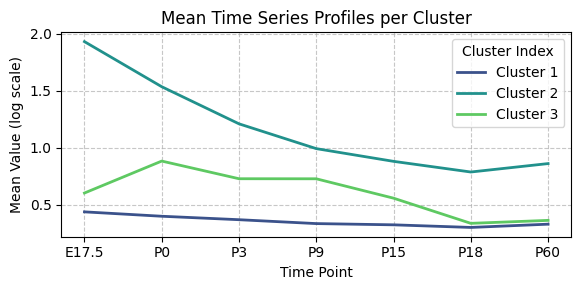

In [38]:
plot_cluster_means(cluster_means)